# EXP_05. ¿Qué aporta el histórico de lluvia de octubre?

**CRISP-DM: preparar, modelar y evaluar.** El porcentaje combina lluvia actual
e histórica. Que su denominador explique parte de su variación **no demuestra**
que ese histórico, por sí solo, prediga mejor el rendimiento.

Pregunta acotada: manteniendo municipio, Ridge, extracción, ventana y particiones,
¿qué cambia con **H, P, H+P o 100·(P−H)/H**? No cambiamos de familia ni buscamos
otra ventana. J5_PCT se conserva como contexto, no como candidato nuevo de esta ronda.

**Lector retrospectivo sin ajustes:** reconstruye cuatro variables desde las
lluvias anuales **guardadas**, comprueba 200 selecciones desde scores guardados
y recalcula métricas de 9,660 OOF guardadas. No extrae GeoTIFF, reintersecta
geometrías, aprende pendientes, recalcula scores internos ni predice las 59 ocultas.

Diseño y ejecución originales: **1/oct/2026 en México (2/oct UTC)**, versión r1.
Adaptación de lectura: **8/oct**. El registro interno previo acota V3; no elimina
las exploraciones anteriores con estas mismas etiquetas ni constituye confirmación.

**Recorrido:** lluvia guardada → representaciones → controles → escenario → resultado.
Basta este `.ipynb`, sin Git, Drive, ZIP u otro cuaderno. Solo dos bloques técnicos
plegados; todas las operaciones científicas quedan visibles. Colab se verifica aparte.

## 1. Preparación y procedencia

Colab prepara NumPy, pandas y Matplotlib con el perfil uv; en local no instala.
Si necesita cambiar una biblioteca cargada, solicita reinicio manual.

| Insumo incorporado | Operación visible | Límite |
| --- | --- | --- |
| Lluvias 2022–2025 y metadatos de 197 parcelas | Rehacer H, P, diferencia y porcentaje | No es nueva extracción espacial |
| 138 etiquetas aparte y particiones | Comprobar unidad y escenario | No son campañas adicionales |
| 1,200 scores y 250 filas de parámetros | Verificar 200 elecciones históricas | No repetir los ajustes |
| OOF y controles registrados | Volver a puntuar y contrastar | No son predicciones nuevas |

Los 21 insumos conservan bytes y SHA-256. Los controles de salida se abren
**después** de cada cálculo; no alimentan variables, máscaras ni estimadores.
El lector usa `round_trip` para no cambiar el último dígito al leer los CSV.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T15:36:49.930591+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos: tamaño, SHA-256 y lectura limitada; no hay modelos ocultos { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'variables_fuente': {'ruta_local': 'data/exp_05_historico_octubre/variables_fuente.csv', 'sha256': 'ac0ede8be20cfdb0b1b0d67c479806f19f44ff226a0403b652438eac4e654175', 'bytes': 45849, 'uso': 'variables_octubre_guardadas', 'origen': 'insumos_v3.zip::variables.csv', 'bytes_zlib_base64': 'eNrlndtuW0eWhu/nKfIAGxu16lyXgdvopDGxA0/mpm8MtmOk1SNbhmMB3W8/31+blBhxy6JJOuYhjbZliizuVev0r0Ot+vEvr39++d8//vXli5fDz6+98/71u3fTT+Hup3j3U9JPP+iP76c/Prz5xG8Wbz7dLq71ypubf7z9+On24+L1u6v3w/vXb95e/7r4fXj7+6fFrzfD8+mvn27fX725+nB1Mzx7+eJv//vil5fDbx9vP9y8/lsa+gf42PtPH2+ufn37X9//9dlr52yoYcy1Rud8rilFfh5KG2MK3tXmQwitxjgk3hVSKzW3WoKLuQ0l6SXjXbGUFJrLQ/GjT81aavwmWk5lCGMovORZxZv3IdYhjrlYi82XajHxFXluLRvdH//zgw03/zf8cr3495vF9WJ4trj+cHvNH4v3w/MXv7x6/uL7n358Lprv3vIqlNfPfFnS6odcoTXGlGqxVL0LNpgvI2SZz8nzMiT3dwVXWu208/iDxTZWy/xYgocO9qjWMQbjY9AWoarZkG0MNflYq7XGRpUyZHaSb2IVdo19a2VuLTe2P/5X6kTrz7dv/yFK/3n12/vFP28Xm6T+4Vevgnv9LIQluWFIbswNHodaU2zVRb7d0hicr9GsQnEQa/MYvEXvU+Hd0esZUxwhvVpJDnJ8taHE0VggNc+zu5paHKoba3WOjWT9AiltMNdGlqo5Iz6Rv+rcWhv0pjzR+8PVr4vr326G/7l6/9vt1fXtG4j6+dXzv/z47NmPL1/84eVXvkKrLWnlYdKYvEGV5eiyTxIpz9/JIYlshkQKIea7aubB+tsS76ojD5ZjaBJ38WkoNqYWrJTSkGFnPFweITLmbD51Evg+6GzR5xgb2lARbJtby3aR2YzM1iVhachhdNWVmBAoB58QtFZGBNgKdIeGppofEmxNIYtitMwVuG8hjsUCAu+6qGtPPEy0GktAvn2zgtD6MbNrIZdkCAZiP9Q81iBpaXySrw1tbq3DCm1c0ps36EWLnqY3t/y16bUDUFeG6EdEJDtU37WcC8qGJYFQh+y6GiaxiXks2JGCjPJgXdksmCwpentngFMb2Y7YMEGFt2fXJLvoebPEjiR0UzzxhqjyJ3SVmGPJc2s9ys05lfwjvZta6Zbk1pMxuCsDtJfBbZJdTGnzDfshMxTwWRGjw9fL5JaWK8QVXrESklvaW5ibCzanIssh+lJklVsYC9zX/xpGrMgEhxE722LlNe/ZvyyTww42JBozly3a3FJP8vbZ7eL209sPb9989+vb7364en/zr5vfFw/ofgls+P316hOvfLsn3Nw2fK71z+ez7c9Vs9OxwJ+T4jU3+riBgoydiP0zzO9DOBj3t8cWtiAXxf0GvD2At7Eoi+EidsiSAeyFz7zjFfQxuihwn6OUMhYXU2sRV2BNODu6EeAfi6xUjCHgpMpoGB/Iw85IFQWm5JyJBzAozdWKUiKRAMQCHmSnoCfPLbUS25L5l2NnWh38TsTampruCpTsqLR0a97ms3CtnzdKK9aWo7XAh9DSowVJjwXge3nTNjR2ka8JQbsaEiB4KGXkGQrGoIFdQUlNQSlPGHwDXYCsit7VRhEQMTEFlMNGKMYTmuGjCd4hHn6IeupSTBYOjoGxBgWCUfEoeDpmD31za+0cqi3TC95pX8F3QHasbSsrgNYIvsXJLpIIM1F54j+wfgo9bvZDceB9ZLhiR2FdVBiUMcvIAnIBI1OuDdJ4j6/LV4rkhNAdMlyRYBBUFH3j5lpPxtvP311dXy3e33z3d1j26QnoF9Ia0Xa8gGF/3fT+WIHtVwlgfOiAoSmYRHBWUUcca1uKM9tKaNq8skktE8J6OXQkzvuWvC+uf4R35cgWaTPYu4gKx66FRCg+IK4ZVS8tDRXJaZnvqYRKxK9KPW6utZNipvscio9HG558BQvLhu2SCsNyfsNU2BoOmM+Deb44sfHaOTCnAKbCZsOUmgiCbbFBTIegvsAMrIgvhNyCoOxzwtqC5TNSlSerjAHlbYTRbEJqsjMOMceCOcFi7zoROfIjPMaXAJ3D3FprTEwpRCRjRzS7bnjKTkwsX52HjwRhOzL1LKDPVhjWt+Ots3wxC9dqKsGdTkZz5yLDMp0puHWk4rqndAZ/STFICEMuo1kKRYoQjEdDGh24GROJzOECojQWaewCXbG5qp5F4czW9wk5TAKztfQYBE3CshYD7NTcIbGEsLmkuldVJgbtR9lKC4mQpoKN55ZaiWxV5rdJUWx/XxLiVnVA/w3qgI9xd5eaw7ISGECo+C1PbGAYhaRwcqjIWsBUEvthGpSCj4QLnv8sELjADT2yxVGYN8h28tgdSxR+yADdhPASTnXzzJK4TjTEVUCxxJ2FcdVNeTWIKzNLPUXpDhn4zuMV1fksStvbGatyggB3m1ovSxxrwd7218vNxI+2/+nED9D8ayd+vqTR5HFQu0RE0R2peD6qiTsLbDTZWoL6zBMSKYHIiIdaHSVd8MUTORHKtyEmkYHpUKEBvObkSAn0A5FaRdhDJqJSziDwOxYitsKw4PyI+WrP8ETVHpJJH5wHI5ryWmBM7FGZW2tFLLqRQlKZIU2e9EtFuN2LsFwkX4T6FI/Hl9xJ6w0eYXmrchUuq6ICb/UvWUdTrbZ2wxgUM9YkbkTruBbSvHOEspAYpbFlBLhCCISBAYohiK7gg4QXcC4utRbm1rpnbbf0RBjhcWq36aeJQZ5CGJ4nZJ9DbBYmfyJQXgwWZgsrf2KpZ+jwPWlyKAWvg/Li+fAZ3Z94PCY4yCmppEYs/ImIxxXhky2L/ZAl4cUWsL0IQJhZaqWrWLbW2LP8mdLRVt4Ec7pF1jamb5C1fQoz7Jy0hZoLgvsx7+h5jr/kgDmM0JEdP7GbuXNSpGFA2fnQk+GYkkFF2BZ7qnwl4s2PMqvwgmdG5hzoA7/fQkbn8UyoOMocpPHmRQmAhJCpSSiwq0hFaUhw9BjzmbWejL5/Ae0uoPbNzROCa2tmqcq38miySJhFTLs2NqNhtRFu8YTgGOI7KPE9ZQcx7ArboF1hTyrGjO1HLpNXFgXDglCGgq9KTYV+bZ2HvWxfSi3rg2POKbIFjS/mk6nOrXUvuV5FHhzTZJjuGPdi8X7xZoHKflgI4/+0+Nh19/uPV79v6O4j7rYdbx30kHq7jFuTO0m9fRIgJtPWC6tAETYR1AbP2GdhfBxGAdWBWHqdUFnmEIpe6OEnzAZByk+5zqbcvRfSC1YgbmA3BPO9MEPBFkMeQop3HQLv4rfwizdVZQrn1lqxMQCj1MEWHoCm76/f3Vzf/OehuN69/Cp4+OeXdPod2+G0wV+1H263YHyNsZ/phUvhTDuRU+y2ACbWVXAqrWo8D6rac2lNCCGpXFgDXI98bezamCSPlpxQxbQjMJOgQZLdMyRAa2wx34HZSfyJgzHkGDMjGBwlihCfw8xStuupgBVdabeO42/Q31djOoBZzZflRcpF9YWleirZhxW1uxukNtXPMDE4DjaYcAYz55KqXopsAIL9PAFutMh549aINvkdoY4XhwCwPUjrKUXC8azWBOIWRfJNmLlN/Y7gPjU69vCfT1Q8jaIk/PfsUndiTMiuYrKvu3jRpT/J7pJitWyKJUD2CHDIsagnZKioTi/vI1AuS1qnykyNPU/An6qlIvamCiMxgfVGlaLEJgKawAjwL4jW0ckrESoQ7PcqqNC9Gd+Sg1L6mIuyudJuFdK8JOlkamt2gG75HC6nL1Xg+wHAtXoUAPfJ4HvPAx+5YybWFYCbDF/L0hsQXFII0lMMyFMkEullMXwtDhI9VHpYzV7rbRAZk40O8lsP93rSLPgxorOeXWRJ+ZAhytjzKe1f81WpiJm1NjDTw7Mud2Z2jcfzAQzItfb+ecRXedagzZU3tdpUAEwpAXCJt5LCOSjAaAAKWkFMC44SnxSKkATA1aXe2QZuMKlF5v255wFVHa7KrCAc8pNKriiL7DtBIJLZtZZUJmW9A3yXSPm9vGkuQ6ijWCcPSCAKBPfyiq4HzUmGs2cliSQJhfGsvvlJvFHQEXBAXIBWIuIEfuALDB/wgi2zHroPSS1XPC1BdEqA/zSlzgnZfY8girpH5tY62Mm0dt/KkY8VJh3m0PM6Xy8raVTcGddQ2ewzbO0s/jwO2G0toqcDkWLcHxHK5e8C6Vv6VpD+s1mjJaov6TgbdL8szH5aNy/omJm++nIibUDUTo272dnXbty1vQcPYOB3QgFB/ewn1/JYt+rBBkkfeQ/2lsxlE09mrs0+QzRW3PVyLAnro503tYYQmKnDFCMCWgHVAGKIpnJRBQUmYXPwOASMHdLI3ghS9QpKL05hg/AoSW1W0U89XKHhdB1OlNgVU9S3TrWXVKoKg7nOrrVGrqAVNi4/kumcj7XXjm/XcHINrPu27q4o7/IWfG9ck7xl3yRvAQgQYg+evSCq9BJcC4IpOSSQTgz9NL86i8AMvE/n5rRWK4gEutDQfSCVInZ2TBmFDElqw+pte5HFsgrE5rKC8c211noaYDeExz0S2TVdzGGfms8xTsMsHGUB+Mv6Wh/P16/IrBc070XtiUd6fGt/FNjcRY2fanYWmb6t5LadUM7IHyCt2cI5epQWL8jUtsvBPy2f4EHZrc3s0TYUHWDgSauXMw6YKOsyaoBEfOerj+bskqY6mzudo/rxANSG4z0DcDAtLUta4wXVH8ylSwrOzOXLslJFeXXwSWo+TY1CGXJNKeqQl2MZ8jRyKxKoqyGo55vBNXksDsiAVvZH7OinuFqyUyucLwqGovRRhyVXZV8sQBkzfjRCGc42aK7izFpPlV+2zlibqxfVtmCunfEUTrNzhkhHPML6EKzz5zkPxCycR6Fzi4EDZvFcD2mbpQsaP2mWj9Xz75LUWvP3Vi4lXcD+/bmt4Dk9bAW3uZW+pHXmUZtz3wRu1o71gPJXvrDDvDuRUu5G9+Lnpyg8Vdw1b6p3OuEUORrr/9fdBqH2Q4SglSxCNbEoFs3WiSF5nk9D3XwdlRRVgjK3yrZIkLvoxAyCYg98t7z8JZo0hRaOa7BcG7MOrsBpTGLRGJvNtZbSre4L3tn7tfx+BVAg3NBs1E0MVZhPc4UQroonjFI6BDnL/6hsiw1GauGYBg2pBIzIFw9Tisb1QJkEF6PU+kpBzUPyn2wZUC42n7MGN2lYBp9wGh3Ciy7jBGaWumNzCJqqgectu5xeuW/HNd/zRLFXmdk8bDHmE/TAs+F1BW5lfqrQQ9IzN/7tTTopDGSZRw+yvBXZz32gCBYHTAD/AQG4naAZ2JJTuI2s64hSGqUlkiEHxG3zSy25iu1A5GOTZQt7oQkfzxnL64mAqdY0/Us9BDWozck0KFzDn/F8DQ3piCoGDe/kHepTd/L5RdAAO4S1lUGdnruoSS4nlTLYu2Qa/KkhGLFqtpUGO1WIg9RWEOOQ2IW5pe5Nk+oWEQse9r60RKOiL6YAav6S+qsx8GefAfNt1/j0mJqst4lOgzszpLjVLBsLl1VaC/5oJ8EcwLVq6rV6xi2iJmq+04wM9ImAkufB3QZNNkRTQINoncxRRkL7ZGiNqtYc47wcstamcWpZ57dM+4QZCqLO+vg4rEEQiuwarN1EkogGENx+68vGWvfcLDhpNRWEvcdeW+h2pwW+PWsqqI5AmALvIJSY4R/fHjScFEiAQstIJ6lj7uYWdQb7AeawWmZaCpCv/sQIl4oO+geHnYNW389zswWhd0UUL6zPvrIvdW6pe+OEWgepzC5d1SvLlM4ZDobLOX5mmkHD7q/OQ7KBrY0+Jj1Wj72VxISL0Jh0cUmTavb5s7pqp8q5uqm/Vqckdf8J0UvRQESYGHTqQzPlk2apmpwJEW4wzRmAuqTYNMws9aR7+ZIjABbqidxqsm8GbZqSeQpyWw5R3I5ncgnIlmkVlKfxRTn7MGV5lEdT0kCShuXnMfgetE42NxfwIn60hhJjz7FpBAgs17hWDRgV8A1VWtq8eEqcOqCGcpq550M1YhUrP0IijkSXGsBR4om5tVbkgveRf5asfte5IMt8Q/QX01Vu09RrqZlXGyKeXeGFtFYzZKOkNi+7dPD82BSdYE+q03VNc6Z/1FzYquXQa+CNWO8wu3nSWgQ6VRB9wXqXPr1TV41ArO5oxa6nubXWKPXAlJDSflOvLZ5vuS0maSeag4hV4urINveZyJV/RWV50SG+vAss4WQ1JVurEtfyDUnj13kmE2irUzErmnKZGB9TfnsgemsyXlgAHj3rYFQapWzoPQqSpRhpbq0VG5u6a7EUVvZVziMvtm2PEtbSCrEI+TiHrBiPMg25l6RgcHHgsZubnrTOmpWu4c29U7knrXGQ4sDUphxWrcv4EdNZym4jg8LqKpGDq743OLOHEgtoUjzTVKOaWWu3sw7LDHWcOW9/pC5yn0PLKxfZjnU0mh0uPZJ6Vgjo5hTu4t35g8d3MMLgsen6p+y7yqAiOOqkew5gbZlUBrvoiRZxegAHKbJvGgCNocETtskzYr1MUDglHdpOvXijy6Z0a7YuKSx1bq07lmpcA0gEYLF/QE30fHwBiu0RjiT/gCBdUPE1ifJlg6iQDk1UONNL6izFy0kGpG3SOl73FXx71B33z/OwX0d7DPlQpYSlZ0z9FH0QEFatQ56j9AkfGj4DdC4aLTndYMGDFY1nAMAKfcq/dRejUjrOBLnoZOHwdBQrKVJQrxlvQh6QBDArUaDuA0ZgNZmyX0GjQk2bW2vVgKCbhpou+dlvoqQGPB5MX9M2+qrZsw/0VQzcXGtvS9Quq/U7u5PJAdgBss75rNul8wkdnd+rqreit/d3YTvU8KMZX4Jo/YAp4YYu+VEHGrGBLG6MWA9CTAKFrNvXFMOnkPqNZ6rgTDe3YDMB+LlfmSK4NTrNO24aYEz4oSvQZFw1bb6UqExBtTyz1Ep0FeAG8OG+I3yJshQVKYMDTlV1bwqU1MO3vPSJPcaDNq9afct4Ws9D9sHEvhFfFNc/4vtVfK3IHGO9oy5b69kbgioiiexyKTBVZLqqzKNTJ6ESIXVurScbDjbpm7u7bEVkuqR5trpPUbOaHF+lC7aqrvPpc69jlh+vpeiKQ76pBxZKU/nQX5Pn843ot4sqvraXVuAr8uHxtb0CqtxiTixv/QbCrEPfupvRqZJLRKksJF45zS1luw9hXtYuczkdVh4A5OZ6xkeMcruUW0+RzOM0s7uQtWZYi51Me17bX15Lv4J0augNCpw0XL/n7qryM70ugGhVJe9SH8ynekWqUXg6OpBCS7ALE1lUS1APvC45UI8bLOo3nGZVkoQ4YKTXzTBD43PKCqrHlF3Q/JuZte4kVgWMoMaUA3TDlHCWl+kRrHbchh4gWFGBe17mYDUokRdcr2n0zu8sXKcEg4LhKP+YVEBVcF2U60v9jgYsk8oAatWpphvfWR7Xg7xG3fsbci/11qQCBd5QhaY8t9Sa4YFWdQo9mJ74pannzk6/JPsk2362KsKWPjameB+Fb6QoulNPN304jznxciZFV0/jS0DSatI3XTw6sUGpdrZFYCn53qcWR0EiL28Sisrk/boOiYUy49jvgCjAdzaJn3WblPr055ZadyWum+a0Rwv4itxyFj2WW+VNyjkjoHJhSaHqOsCTrc+6DC2qfNJrcGhLUs+LPEvr9/aoaTKpz0EmWYhGxVyxJyc2KuRkml7cwDc1tKwBuDqz7g1ZyTK5qJtXrBJsbE73kbukeldPpm4utd4toUlT+NTwZfWUcB+kVLukUwu1X4pc704F9hptt739DBVMTZaEirC9rhILZllfTZNmS3IXs6BDdXB5Mr26EynLV6YJ3XrcpGc3a0Bmp7uU3agDgJJx3WKbden9xlI7H95dCWuQoBSpTfS6dqKhWPLjioZ175KKxKr+6SwBQmstxN7Cy6YWNSNEfhagUFGwp1lS09k+0YJIBKCO1C2oRJ2XxecywmD5DoXMveNkZqW7++yTsJnuyPpMEuipgYqYi1M/dLJNg0g93gP1B9DAw7U8t6dpkyV9SJtOpW0udeghkUidvhjZc4hSXN1Kj/9o2B5R2n2j9WuwU9J1ni2FfgzIy2YQUkkQXdWpXWW28giqd6HXuGK/Qy4SSgeNNO+vFO1jHoN6Ioo2Tnd16hs319o5lF4GJac0Qnp3ULcyre30Bj5sez6zuaOd9Xno3tc24RxUAUXAZsAoPwVU6AQIrPRTeH4yvTq6DmOzx7uHqfu1YD7ksFXOiN2q9jslCPGxWC66peXhbRmnjs1yS6saiY6x1hZq7qdjNte6p9VST1y0Pbtfd54ebUc1PHo7voaLOsOn2zjd6NVgzc+WfM1lumgSc28q/6Wq86M9E02IokOjTajNTc+I+a9KKMMTXVaq/gqdPyUmqZ3ArJwZSFG5iC7aRUdeXRm1mTXo7FfNcW6pVXtFTo0Pm8Tf73c1jLWjBUJfZYYim580F9g79eraFHnogVzjEXVNypQLV8Us965fNlllWusJHjUUB9O9N3I+qUzNoipwod1gCzZu9AVbp55L5IQISCGoD+oo7TUF3/zmQg/qYM/fXV33kSR/h4BPT90DE+9BQ7uU4/H/DwTJKRw='}, 'etiquetas': {'ruta_local': 'data/exp_05_historico_octubre/etiquetas.csv', 'sha256': '42985c24e4669007667b7883ac34b18ba5a1e080c299724aaf6deebbab6e93ab', 'bytes': 2942, 'uso': 'etiquetas_oficiales', 'origen': 'insumos_v3.zip::etiquetas.csv', 'bytes_zlib_base64': 'eNp1VsuOHCEMvOdbWiMK/IDjKrvajJTsRNHe5///Ipil6e7E7hMzxsYulwvur8/fj5/398fHY/vz9vF6/3V/+/h8PD+fP16+vbx/f6aErdx4rvNGN8nt8k0TbWWueOMbJJ0/TJN0f2oXU54mPR1T+zamyyl1mlo36TwTqf9I12xkmkam15Nomop5JS86qJtq8VIHb/km5Jq0e7XqnlXDgtF2wHI6Ss+wWOTFyjlEJZcVq7fhlrK7SewY179Y6FS8NIuhReJ60bZvYkNbL5t0mk59LbWv/2HPjEVpr4DQgZ4ORIczcdhskuVsrSD2CqF6its6RdmtlxFG4HJkw3REYyN84CLdlPRimqmyhu3kU6pshCd4vBOjP8NDRHJPtfpexnF26S8LR9G1OuUiBhvNIzSFzdSYqWp0CrxOkKqBo+xuq3tq2sIM6mmkqgnYtQV7e6plI/DaUwdMc/TqmtWWQqa3UbXb62a6x9XTzaahULVVaWurnJ6sxZprREdiSPVVR2ZcpF0tkEaR7DAIiSPe4UvFs4MBvpTbIxeGck9AMZQbHoyA1aTwQnRRn4mD1sryZE8WgEN6gBbCkRHRCDkfEbrG5rUmG2tyXYZMuZBmNdVxu1Ws6Fo9PIY2w7tzUUyQmtujQpE2YIi1eyeh6KlH5Zh8FINPxEuChg544wU6ng6gY7rRpfz4/2s0vBpo5z84VDoMvXbnB2zIVfVCM8cBdZ063hribRIrWrIXWsYFsu/L1nJv8CFrCmWRWUZrvNsfXZsXfnJuk4RPDHS9Xj66X7BQu2BBXk5q6cIFU61PRV0vy6C45NUW3QSoQwKK51URqsiQZfc5gmrXcPK9Vk9ri146aCUU00Yhx5txWaprkoPmQ+b/I9xfdUhuLA=='}, 'externas': {'ruta_local': 'data/exp_05_historico_octubre/externas.csv', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': 'insumos_v3.zip::exteriores.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_05_historico_octubre/internas.csv', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': 'insumos_v3.zip::interiores.csv', 'bytes_zlib_base64': '...'}, 'v2_oof': {'ruta_local': 'data/exp_05_historico_octubre/v2_oof.csv', 'sha256': '796499953794c62eae836c4378121ea0487809c716055a0cfc32617a00a49276', 'bytes': 1386384, 'uso': 'resultados_guardados', 'origen': 'insumos_v3.zip::referentes_v2.csv', 'bytes_zlib_base64': '...'}, 'protocolo': {'ruta_local': 'data/exp_05_historico_octubre/protocolo.md', 'sha256': 'f391d0951ed974aac3e3772b57e14d0fee95819bc120bc68b2f62eb18553b888', 'bytes': 8404, 'uso': 'protocolo_historico', 'origen': 'insumos_v3.zip::protocolo.md', 'bytes_zlib_base64': 'eNqVWdtuHMcRfd+vaMBAQK6Xe+FFlijTAUNTog3LJkiZERIERO9M73Komel198xaKxCB/yH5AT8aQR5ivSUPBrR/4i/JOdU9s0NJCRJAWs7u9PSl6tSpUzUfqau9Q/X2l+/q9U9KL6yrtDK5usl8tX7jssSq1Kg8r5eZ5pVNqnrqzG97vScmuZGf0syb9T/soZp0BvByd7z7YKguzBxzOauysjKutErjr+d9fVv7SjuVW68SXaZZqitcXu0N1VcaO1is32Bk5tXC2cSkMufVrlrxr3m1yK3TSWZLwwEG+8MstlQGc3pVZL7AH1Nl39UGPwxVv3/qVV3ySeOywpSVbWaprMvsQGFvdak5ySxzBeZevymx69QsDDaHB8yw3+/1PvpITYbq3Jl5XcJYK6Vz7D4xvd6lWWiHA2E7aZZU2VJzGaMqxz1an02zHIdMjT98x8YJ7G475huoXL9v9WjUA6yJ285gHY8F4k7huwTfap0rnBlTFtMMx9HF1OL4X1taJit0ARObmUkqsXrtdY7NlRk2BEfxJmxU2NTkVs3wfC6PTmufyJNlbZaw65LLltoPVFGXWZItMovrpXaZnmK+ATZ3m+W5lplnusC5NX3uF4CZOH9pHAb5Oq90iv2JWXeH6nOBwAqeqeBdORjtiqF1hUle61LgMnn0CX4KwPIfRKhK6pXuTkPowALrH7l0NssSndJ5cRZ8OQwI9SaOhy8Tk+tff/jLYv33VyYfqPWPzsgx1CIzrwmvUp2eXz493Nt9MNkfwORT46raafXZ0Xj46BGmP/vsaKKKYghUA4FA2LI2+RLYD1szAf1PjX3+xZMnNBbMPMVBxL+JYTD6BRys836fsZQAbHXOg3ps4xxo2B3xc08+9+XzQNHwM0CrqHlFa2ZzIiIrkyw1+NDq04nZeSQBc7XLeINN9x5u4kVZWCgTbHij5rV2KUyvYRNEgQw/eKR8VrZPcBjAVCpvgRzGAfeYOGDe4TcSi+A3sR2UlHWZ6DC4IQOYYFETxeHS2bROMkIFIVgwCAUsZ0dbcvaP5ezyub892huo8yOxwEAdXy+S6mgyHve3znfOtkdnQ3UGWxLdhB0Ck7uRyNRgL9+Gf2kR+7lKcsRKZfP1mzmgMlTAoISbWxKCG4ahRbJIQ3ApoGU558GryVjCtB2Y1LplwTBG6OyxKkB9EdZA3E22lADwtVc32t+YsDPA1JSG5OJNIZEVQgZceRImDiTZ2ChSYuCfWXbLIOv17tTJ+k2aza26U1eNG3Ddktld725nZ6f9jwcuHl2fnzzHGDEo/l6Y4JQQJDhDHBHIuXmEk/6HwRfHv78/+AwD+f/tL9+W79Nay5Ka0BJ6rnBGo5h14KgN2SqdiifwI/61xPTbdp1zWWglO3v7yzEeTwGtcwTjmSrMLTIB4y5MGBZvEkrDYYEwEFUOVCRDOHvvuU1JnIT/s2ZZtUWuNNugSMxHHIQ7gW/hL4ONYpZUIvQiSxGh3gpzbUJEkdGdjEl5xRzROdpQnZagFaEy3saUwf8tzJRtUdnvM0b1gqEE9MddvRitJKN6oKXJpnaa62BI+eawo7wuSqHXFwyfLK2ZGBATYJS8XpkQErMsD/S4SQrkiHluKlsOyMi2fVrJ4RyOcMLdNyvQ4D799AjsNNntF/rV1mTATz31Wy+uYYqs3N7e5kFScwuPyxxCRLqkW2QfFuOQ8k5ziT0ojnwBqdIYnBmRgdskddnx2flQfTO9BZstoWTu7pY7f1BT0Nrd3dufP5bn7+6a70P1O+1NngGD5rsawMvJ57wL1ldPXb2wdPASwMVcYmc1z+0Uh6Zyuecn7hzJ3zVJp6yL9U9OGAdpF8fMikWNVKtaHJSSl7Mq5FbP1EgChVIhQkJiE3rxWU6qtz6wAPhig02Y2SIVNNu7Xg3m6mNwTnF9Kwe5vu3D3Lc74e6LwXxwuz3y6fXtQNkiY/yltvEZ7RfIKaXVT2wRVdDGwMAHlhblo6C15lmAVkhLXA9zD2NoeiCgqFfBKhGH9/C/QdehsGRiDXNVWAnW4QQkCaSeOiJaz50t128K2MbfV3SRRvcJ5rxxQlCqDHaZx2Kvvd5FUDQw8/on2Dkh+K52D9U0YmGgxsPxhJ/44L8x/48JQ0gMpy6eXZ5uwrLfr2xFopoDLnBYv0/5gGxYARs0rojiwOz4/bYWUqdu0pSQsk9MDVOD32O4dPeS12beAL/QK+titM6Y3VRFkYFjUIXe31ci1m9gIhAewJNOEB1SfMjXPpgLzsHUX1nfjfkG/NgwcTmvW5pulRX2IJwpWY+79I85PXJhIHdsTFaoSGERMeE5F1NKI6YlPcqdmV5aiibXJHnRlnDwcRPlckzshELjbHR2friZzaln334dZdUH+HTmJJNKgvDigiiKUh1qEnNrkprzIheOzqm+7QY98BSgTiEEvO6+mgz2Ho5biwSEiiB7qKrRjY7Zf/fVwVg1VjbRTBv48ZmQekfdpAoJbSpGI+IfFgFiy8e0kKTNkrJKtDwhFlIeNnclB6LZ4EEcSYBfLEDbWVWnotpyvcQWvvnmyeBDGnFwTwbdkzhN0N43Z5OTBlHjYMVWrwZ5uXC1IU3XpDrHTCXpdbM4mLNa/xQssZKEYBPKuqrVqZIrKSbqRY0kztyDrCXxfgCPeORWzBx2h7Cqo+C42uv1+v1zR7GMbH1431EdjXc/VqJq4UnhvvvnRd3IkrZY/wjTS/BgUcxTsEATwSxEy6e/+BzW3BD1qmvZwfu1M4vlyxCWQKZIzc0y78RZp8amjJkZJ6VAq8NF+9hF1pnhSxjqEscEYg/eQWzQKpO9g6ZQ8uwEAGNSbV9SxpRRLmMLuJt363GlfTYPxP5OqD2OTAMio3nKzvRwp5xbcpkNqToPpUhnUJhurkO1x8zZ5SaWxkIxZbc5cEqNl5ok81GoOupJ5hrcF5NFFsTGKlvoe6UsswAjLFRuYBfUpAvTqf8BB9ScIlOtyBLTYm/RwIx6qN+n4Slp4Cqwt2pgTNfEUwndNbIDk7Ms/BqleEKButAqamNi6vjpyfV4f1PUSb3LHye7Y5TJpEfZONy2gEuLkGAQ4wE4sDZiy6q3fyve0w2CfVZLzdxv/yU+b6ppnAZ4ggMbFU+d01QwbDb4xM7JUXU3MVAL0oYI4NSIKXJhAlaPEXVdEb3iFpHKWL+9TzHSvFBbrGpb8v7zBFUZPH9ytT1kWyGpUXrBDf6wg9EPsPNWEkRNTDmdmmR78OHEt7X3wXAJnaCIVTx7csMouKlBWOXICUmtOhMGKqxQCgRkd+roiHuKnVBnL4g330QP8pqFzqEuhKCsnNAkpbyRrkxwcHQCsuUcCEopEr4WJmjumC5UNVtYgfyoO+frf5ZKuoaxW4Q5TGBX6fp16EXyoPaV+IxJvXaagqodIhUqnMAUvFLPvngRwkqeBAdJfRkyakNh7zQouQKYOTTxZOSG33j/2fHpSISOZmplWmMyDmfodKFkA8F6ogrMY9nMCnvgz7kJXQOGSJP9fdtOEkkc8uRK2VhLhOodz4a+D5DdUPeQFpgjsC2IRUv9utjkHG7207A29v7pETfWaEVaNNRMJQtehhcm/uzo4QjoxtZNm4kD6N7RcxKoepFTwrZCsIOhyFkBr21USOpnFC+YtiqYj0xqwA/RoCtJING7m6NEbnVyVFKXtGAAhUoADfiL8WL1k4XGl5gliAuOevLFxfFQTDISR779WbQikzoBHsVxUE0iPoSKrbSu2OKlc2Dukw0MY0fkEHXfzpna0o0d2VNTolY7zRR1hkjFwPP7A8/eH3jOgTtE69Z/aWO0dOT0a9yKk3/oISwnwHj3CQCVha2nWrgvER6DzTdhhRtGMMrIb5AhRIviUkuFBEeGLrAQGxxQGFgrzI7oQHyF5vFiBwlHZA/GiJH5PeZTx7JFUSHkmZnXrPI+RKMSmO+VX59neo7iDCDCWhvPYO/rHwtJpqNQIQxaCMh5WlgPOuWeWA2s5RyLmVqnqEqtDI+sS21r8lRYQZorFnXzAL++x7LyFoI1mZTeEaAwW83XBa91I1DcRnsIqwZV7Ta0G0hcFvX3VhXyZhINgR2BtbFGyPVl6NaDS2J4SOEo3mIjWlrTQYyKCVahDpZg7HS/AzF/Iu8tWj28ajVabLTvv9tFlBJko3hf7XfF/asHXUl5BPmyP3g4HrdielMMlNqzwOXNpkTF4vuDMX4Iis6HDhhf0+yOyWLNz5vVqXROmorqkGhzbXdRlhK5Jk0tsOXjWIhFESh9qoxK2JTd2vr+eQdN/6CzutM0WihGujXHrDbS4+YKpltmDBXbmFIPBpey7HgcJFmIQZfrpkMeigDpUtnQ8mCZGOCbUpJVAmA2u5hfmnceURPyAZairPPwVwIV2VgY1XXeoCFCQt93oIKzbEcVkBM7SVBIXl7zMLMFPbxqaLTB0lPJfnzTZSub4GSdFWLlxpqQ0pCejkVeU700Mj4UZM0bQkwnC4ov8Qzbsd8+PwmvZeYuFqbWsXkZ3yU22TWHaStTIGxDwmAKgFqXblQAeGgMBprzTXXL4qMuyWBlVooWiFJGL/lCT6R6aSsztfYlEeSYuGEKnVQxS1Ijx456+yIJJmgkAe9vrNCqConNDT5o8KdZheU2v+U20XlX6rPViV07O9Vtyj+xuZ52qtqOour1ntTlSwjM4UCdE2WeHdhzfPsKQPIzsBHKTLmZOppqoD7Htyvj0gwDv8T15U39MgcHXeL6DBkCsz3F5YX9PscUYcyZBgBl6q/4zcITA3WMy98gQyU32uTIZhyqtnbHkwMkruc3Jr5bMYDFa8CIHDGD903KKCKjV5BDCMLvs+pG+fDF//rDX6EfzPc49zJztpRKP+dLMiBCzZgPbJmRmsu5hK0p2HfpX0pnkN7gu0UcZxdENDkYjx9Apd5U1cIfjkapzYbWzaGfhpPx3sORR5ToIXc8fPCg1/NJ9jKrdnKjHTP/EhCBCsLsW/g/G+JUfWGv/mbG7iMytWd+MSMArAZ9jUItVJl05F+GQSRF7a4FgcNAhjdVkf9Pq5/AgX4ntAZprcPIwZUYQ177spGGx6T/B2z/H1tNOPn1ZvK4rVMAc4Eic+7sCeKd7LPFN/7cz2nnHTur45YmsH9pXiObdV4Xd97IipzpaoaWZqPc66s/HjdvyRoWiI0eu2K/8E/D3r8BnFbVpg=='}, 'manifiesto': {'ruta_local': 'data/exp_05_historico_octubre/manifiesto.json', 'sha256': 'ec817f856cd65667c09ecc66e80d904fd577105c4c8c2911b8af1caeca50dc67', 'bytes': 2003, 'uso': 'registro_historico', 'origen': 'insumos_v3.zip::manifiesto_insumos.json', 'bytes_zlib_base64': 'eNqVVU1vGzcQvedXELpWUfg9ZH0qahcw0CZFE/jQizAkh8oW8q66uxLiBPlRQX9C/lhn5bUjAzLaXLQrLvE4b96bx08vhFhc4ohvaVx9bHbr4T1q5xc/ikUBWxImVOAtSe0LhkwmVKjGgq9BOm2qhYg+K6uChhCAZDTaS69ScovlhI19ft8cuoERP/F/XqGx+XtPIw6rPBwel/lDuhtp2qej1cuHxa5vNtRO9ZxUKabVpsWt6GqTG34Wase+44fY4YRO4kZfiKHbdkKZIK5ev/vj6vVPv13zy5vFI/g3slbH4LK2ZL2PUoL3kJiQwWxsUiGhQ0UyyKxjBG0Rqy9EifvjKRpMiyPk5+VM8cNIfdP19CxHBU5Hd4bljRa5m7hsaXi1w35kfl1Lw/qI2d53bSmOOKJpR8wjN/cMI6mLhFJzSUF6i7ZglSG5RCk7cCwf5IxJxozGVA2UeTMqlD5mIyXlp4z4pP9g5KUCo76H0RHzOxihcVbpWqaCMyEkA5FliLwaCBGBEtbskjNGBjBemRSMCjYn5VknfMpo13djl9kgq9tyjk+w0p5zYTPQ1y+duDEC554IFMN+EPjXfpgo9ITMdCmU6PK4Tz1pHp5zfKqJqsjoFJUIbKlsyADo5ICULbISRRdUTFlpmbIPSVevid3oHDML4Smfnir1PAXc2IN+1nYmeBPscyr1fVOQCWyaYeyRX6fSlZTqnfImOlg7p6KCP1/teipNnnXsuvp/JYTobYzRsXI2MxmkYHy2BoLSilDaAIEtCcpL51DmmjlOFKCUaKMG/5TyAfsG0/Z5T1oXbDxP9sDScXZgbr7+04pHpPWs2VpFmFDFD2LT73fd8LBwIW6p35DYt91LfMm/4vryrFmzpEIhsfq5liSTSrJ4yByYPI9VxWptrVp7Ji1N8k5bwy7Oljz7GdzM9MXMdpG70mw6npncs82wdN+S+iFXP+yY0y1boFsfzGp3N5WhQIWas+Kw1pzaLvkklXe5oC5clYsp1ZRK1J58QnCO7cFVs0C+cIYfy7gvgI6nTpi/zwnLB267Hkfu6zQPK3H1kOwPscxuGIhHnq00XAju1RQEDbWc0icGEnWKcn5yem9xcHF1f3WwBduhdv0t3u+bzv6VWJ8ep60/v72Z8DjwW4ZfzrrseB6vL8UdH8ySbpuPs8J12+GoYHMhTiKIt71584sYmlacHsb75xIOej3fJycXY6aYnY2pSAsQwRsOUgshR5eDkd44CkiWAxegAH+KwWIkVJo9YEjBI/Q8aCdSLmx1RpP0lKYwCB6DBZ4YJzO/6ErVmiQ1O4Z0UZCoRh7PGJLRzmWUnHGf/wWugEI/'}, 'oof': {'ruta_local': 'data/exp_05_historico_octubre/oof.csv', 'sha256': '7f9acdc8bfe3385f396c173e4e9a0b60004e19a1f49b884a69a70ab56264ae13', 'bytes': 966146, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'parametros': {'ruta_local': 'data/exp_05_historico_octubre/parametros.csv', 'sha256': '184f4c73cde51ba9514062ef326f76ac001e660083364a8b140e5ba4af7b6b98', 'bytes': 21092, 'uso': 'parametros_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/parametros_exteriores.csv', 'bytes_zlib_base64': 'eNqlnEtvHUeShffzWzhCZUQ+l4MGBlwKjdkLtEV4BEiUYcuz6F8/38mqS/JWxqWktttW2xIrKiseJ048qr58/fj4+evdH4+/P3779Ounr093v3/+9PjbX493//fwx6eHXz4/3j18/v1/H+5+efz28OHxz28PTx/5g389fHy4e/zz14fPD3e/Pz59/PT49O3xw19Pnz4+fPzw9Y9Pv316evh89+vXz399eXr48PHxt8enxz90zdMHfvKPx6eHL7rk63/8c3x4/4//udv43399+P3Xb3dp297xX++2XGqpm4/cC/+/5XrX3uVavHhK5j2nVpN+bqsplWZ5884fblu/+++Hz38+3qW0vUhPz9Kn8JRa8pbG8NoH92mS3bjCkYPEkZtEp1Jbb1tq/GbqLUeS7XzuxkVb7aknrtz6cGSXNFIfvWy9btY5ooRzH6+Nx7MxavMWSffrc3N9TmaettGMB/aMcHffrHrvo6GWbSqFB+w+2jAez3K28Sw8vQjPh/BfHv58/Pzp6ZHf4qh9mDezbqVYyoXfXC5Nr6x1PDQ32YZbL20r1vtUaO/SQ64+xmbYT8biSTOq6WjfSh2W1qdOi7UsJcdSdXiqJU3hPG5uuAPGy5nfng/NnfJA1xl/8LZZJNtOJx9147ip54GNLI2ik0/dpq3mNqqXXaOGbBueeaSycddI+MVc+nkdvHBZyXWr1qwlnbviZbUivHKTmvL80YHWtsHPlYRKqkUavxgr7SrhoqRQKGigN1NweLFWEkbzsaW8S3YcrozWBkbFzdIq2RZbDn4YV+KnPbfNPUkjvhFw/He2isYO4Tl3XA6v5tZeAge2V6a8hHWq3WrGBQjXxD9It8wf69Scm392TykEUm6OpovUHlnT1ugrA4jgWv7CIbfRpfNa0PUoPJI333bxrXXiCMTARhxjjEi8n8XX5DUjVg+AWvPUDbbl717d5fFliu/4rLS+tQEM8KeR5vPJz4VGeN6WiehqWa6I9xiu5wRkKxtxLMUTVBu2diJs4E2+yvYVT3GNwcMiuhBMtg0dHTXjd4UDeqvedjwdhMOGj+OKRFStq2Z8tSvuDS4DesI0rpXinYcvnBHYMt8uCMBP8kDofvNseFok3s4IUMoA3/rmqDpXuXvBF3H/1pMRpmUH7Fq6kAh/5CfTViLZ5yAFPFM3I0SLTCVIzcNBcZCBx+f8O147aYFUgMt09LKFWs+L1kknHQfjJhk1VEkvZoSqsItE4dvYtY6z61km0mHoAATyOVS5y3AOiT/gC4Dw9MYqgMVHeZie/YjUgfpsA4bJPjlIkXm1aOWU2YAqAI+Y8h1jiC/lQ56J8LLd1wHdAn5iZMDNq0Xibc3vQ8E90CbpgGwvzeCdnBNjA+LZ9lCqPMoAdYCGXkh/KRLv1/CIQjhTRcFodZPSG6ECykIaODtQMPUCmBPJBDL5iFSZIp3nk7sAqdjTScM5N+kS/EKzWJqgsZnSd1BPo/umJELG4DCr7LLYM5mIQ69NqTuV6YpEinJ5ATkxye6KimVPZBDQAi4URGhZ7Umk42yjguCKyi5vQbfCwAySY4qRd2jsiWDFvC7iAyWKxJ/zaCfigC+u3MCSPGU3fMIT4AXm77CbEM4hsPnoOkskeQVdUhGHBtWrLpx5NBdMMCQiiVHtBxe8g8P8GfflppHK1wglHWfIBOkRyoDFZFBoRZL3c29gfVzUAtEEvma6bi3wlrpG6FA+llvLY6p07jXJl/EQ4rztTp4yORTnJpYN5+8BKNZnix6euOnZOQf5CA/Bnru7oCRp3FC+PVMXU47GrIrakiLhK+ICKYWsQZyOSb5N7AgcAb+lg110c9HntrWsv1J47jOJhdK3VLrYad2dnNyTYMYkkZIVUvPQRFXLznNk1F4s0vY5gW4CvymZlFa2NsGWwARRBIHkVNu1TTYSFSD7NFA9YMdtsaQQTnKzuPEsRhSXqKgabo6dJRk996wwgIFi8Rboo63FCD7WhT9V9U6bugYROTVnHnDosp8aysgPYEcOQKqNRK98qLbmQmbCYXTlAwKT+JNDgKyy7l5FETkN9gWmkwY76ovEL6EJLmXkGojlMLuZ3cRIcEqDHpI8+07myLE4dsesnUdKJdL4CWk3+TS5obm0g/farvQtY8gtk0HrLh0FNtEYU1wV7LoK72tguosjkOmbCIBEUyaJnmTF4NbbQaBFaXLW2WWQVSs9QNosJdT5axfuzmqI6+Fw+A85vxyQMn+HLNWTC8ZGJP4cmeRjuDLMBEZL/ppODinFmLAKeCmYchSv3J5439NPlPT7kjZJKiLoEAWluXluMin3GxgazaSjLqZ0JqSUOAYVZ4sUnpeyguK0Uqootw9pQMGJwWAnrvx75E3nJ6AZmBRyl1rgKSNoFkDSqBMIfcw/LO/C4eXSuuq17UImCtxgqMCDk0EnA4OOF4MetJwyApRQNaSwOWCW3ADkquSG+O5YWPfGhMt9SiuR6MWYJv4BYKiBkSfHIv4IeoE3JxXUTI3zr6R8wcPYcnjqtVdAOa6oHDLfmIkNngUhwXlSB1br0SrgKVTsJZUBvUcKPwMtR4MwZFwcHs/JEA1mVKm3q6vSykGwkgCMtEawAcxn2bPv8/7Dw6/f/nr4/OHLl9etiEGipLRFLLehZlFFe3rs2di5ffnsMQAUXC6LRJfb1eW7O/2ncE03hNg2tXMGnAx54magA6GEkkgg8wehRyOr64QHo1wxkeUmfuMmprKGnAXPtlmg33W0qADBIQhycKjvN1FXCstTkVBlkfLLqsd8SxEdvIe7VOU6KBNkamnpzIbObT0aZQrOzbOrQ+arHtNtM3TliKwyDU1ROQib1svt9t2h61RK+BSJwChoosuvFTzTh9RGhTjvDCNqwseGOKoLOCoI1zal87brF7vNvhTAN8S+y6qgfDLixVFwauElyEN6Jia4R54xhdeqN1WLH45CIiFPwvlMOT0v97C3jFBEQ9GfoULK/rSqwd4yAg4l7wUHgdckLr5ebrcvV4FpvR/ZPr673z68MiqVoYgRObal1QFt0e9LkJChDU1amjIceUpP8OqGVDXP8iVIXK0lU8FE4uhnfj6bIjfPiKwKXmwKSZA3QAs/KfgVWrj43sxAoCHFAyqD8hM2qh+orTj84QSiQK7GLxQMH0nrTd6IBTXEi6lkIxu0Gh3xJtZk2R3qigOoLJ0+we+orPTJxI9QMGWxISpfSWJlqVtnk+PmCUm5cFmiguCj/A2gJt82Qn+Hk6J+8hPgJ76+PmFejHCxgfoPVFBUCrCekWYgJmk/U1kVhWjdn3CWE/gP+V8d+rLewt4Cw9lR0KXqoeXohG9EwmwSqHWLPWBBLdLPDaSB7BG4DoDZrMyHnExMrKjbC1XCsvsD8sxNnKVl49Gxw/ke5U24xwDINFI4KLUFcF/eQhq4WxK3IhZVCNTo8jeQRsUOeZd8R9jUYdHlfkNBvRMfTW2pliuHUMTAxTWUyE3NqXEgRZ39TnUQSA24y1gVdBuOxMXwTqMI0RRDj2yz1QTFlk/Z4WboPutZBtAt0rXAUT1Z4eUm8CUqApFUipqZQfAc7CFqb8qGxct+E1wpzREPNAm+s53rzdk1uJ1bm/q/FArSgudA2fUmQ8oQKy5MmSMlIYvcMTfFGa5HXZn8Em/AH7zfZrEJJuT1Jm9FjKnngMerQ5quAu5Zj28BErnflRs4IpEbAFK7aQaYgrCSpI4vo6sxj0MOzjI1FUqyI+JU0GGvpNlcqWUssN7eCplqc17oGkoqslcztLcgCTtQrHGtvBK3ji5/Q8GqDwgDdzygmEcKeoNb9qZGLamvm8/u5Pnq/hbW5KqWxwajUZcptfXo/S3/JbI1WyHHDk1CPLr8lv9yLabEs6hNCN0stHDNgQA99blUAV+M6yTbjdvgwwHB728QfE1TOqQCcWpLTYWpQnWNFamOil3AorZZIlGA41qeVjW+ZYRa8JsuSqth5jqznSXzbcSnHM+qOoSHnHNV47hJfUzeDiGlOuDGNZWJ4SRjiiINhNpFh1X97EJ2gG/UFafGbUPB2Iu67mKfml8pCiGUpn9XNdTb800Igkwszcne0hWfJfJNHZY5GNP0tcyud6TDt3AmY1FN3Mts5pyvvp+V7v3pMtXjXTdtajBg/sWD72eJe3+C3tkmnaMSudgcQvrMPaPOuWe5UGL1FdPMGmJ4W1qF21l4Ka6mFAU75ffR+QXrVfrOAkwItQsnqVLd70UTXDGS7hfph3AV8jws3pFVivC89Z2m79QW+B0gkC8OMwBtgkRDQn71c/a8nxXvWZ8I089qwElq1mB/tUMK7QBzJIDgPRTj5N222iEFdsBTAE0Xh9akSU+jYbCaofCOOYQ6VEV5qeWPVoQC3GSVbpF3wOlU+VbNhUi20akuKt7PRDgkbtNy4RBUQ7M5qE0aOEUpwrBtL0fFLsqcxpDc2uvtk2c9Hfp9Lqcb9ZWm60Q7ZmplHlBjmTIaLFNbKLtodarnqK4JlV+tzRyi7WKC1xWUhp7NlQ9wkE1taqhFlza5Lb9zcWl120AElfTAaBqLKu1iqCvH0CYMBQ9WMmFvoEpbYyFr+Ug3TJXo2ZrPmbaG6LOQb5qzHoEG9nJOcKk1U2Cu0j1yOzV71NjAYNa2tLqrXczwHEOC20atA9FSEKkprlmjxr3UcXjk2M+ksAcLqYAqxULvi4V9NYORqyjdspy6zyUXHtjymIpWYZAuXS+NhkAVyHUT+C/P62u4aN6t9rJax2qF9GkWRCrpmDY86pFxSbLat1LnaK5opFW6nbSidSB00rq2ltLunKLJWgEhdvJBmOesRf1OABTym2yVvGCWoLPArflVmxFygsnXMAIF2dBw4MCsriw/Zn0INnheNZ5D7DHie/q4JtNB7sgvljoO1QBQkW4V2YR51/PCb8EcQqhpLFAuweiG1rXPkVxqPz9wDnDN0aCrxbJvOszBf1ZhDbBAx7W/cOmbCWNICxRdpCJfhUewpmREPM1BcdG6wLZet1hB84OilEHCy2XugEHBhwYqPBhlcD/OpEEqta/afpTZ3fKqzTOyaahJJOoXDXsg+vVd5fI8W9ymDbMLasIMgXzSovzTlqxU4uwC7GAAV2dJawPrA5fVCo7jqrnI3fi7ysIozOR4Gp4LKw8jUGUjdqgsbfLTVfiCbKZpa9J+BJ4N+5uxyFM1ycV5Zwjtka4kPybNB+LaauOy2AoHQSJFpWp56qbpP7hTJzuTZjV9OZxTFoR6qjhXUV5XdZ7Rr2o7qoIgI2upRoMHQpL4VFuS2ruWo9PGWW1ubroWd3ws8FeDLIRcw9G1htXkRNN2vc6xMnkVbnFxfCAS/KdWIAC18XnWSl0Nalxh6jxrbdHmmBfbzbpUY1pF0KFyblaxAAWvcCSNVfgJ/tQGJcwJEAESRauoEOonPEBx9cX64b9driLOiSVTCY69BJ5pzYJKBdtvwpE5E9Sy2zbjf05Kj8DDU/lRNWJnA3bVeF6gRnONTcsXGtXslEIrHK5SRjscftF3n3gkTqWVinGW3c4QqcUbhGgzb1YDedqSsIUjT5jejvhJ6rHYmOHTqSGW8GlBKsMwlPvqxQn/0gxOjTFBi70k8cMNm9B57pdx9OIrSW4x81PbwsX8ULq2ZLf1upBQFO0QqQUHdanW1lzSno1wMYFl7VthYA6PJyZBgSct1ZCyRWdGeW6bkQO0Tpy1kNH9LLuvIZW1z6bARCdZnc+ZmDWZ1vxY4XC4JvfqXYgnVppFZc5P3ANip6ynvSCo4NBSnQXMvQfEDiZIdGwQ30wSPXZ+cYWm/QEwqV0KqAIaZi1B9ly3Ffz6Ei+gTleZlEBWVOXaD4MODPSobQ4M0w9+pq5AEu9LWlmtgTajcKHeEmki3Huf9dPQWrTme1pO5YaHNud2pBpCpm7Dgn4jLkc1cnUN0PNugkWZ4yUYXpiXZmaTaGqJd39gsqRpigm2+3GmpNpa09JBpQxzrqvshdURXNpG63ODRMskCmICliKdB5aQI4iFGkAxUcMv1cYq21ey67bNmTqiqPomaKqDZ0matHoZ8Wpg4FVTXzBVrwusysxB9s4YWzlWddBcE5wdtjmbaGoWX2aPWdNCnk49XxUnJ+nvX1oHR8ja3LwuKmc0NS5LH+FoS5pyq3IazFsdmTOyreP3Y+FBywuqsTRshOCnZRa/76xqwZECPbc5na2R+HR9cI29xly7pDAcMzauGxdH+a8pC25CAajxHlVAKDo4ed33mjCpNvjMz2sA+diNoQDQHhJW4kFrS4H8c4rVUoZJAzABbYIsfZGjFrS5fuvaBCFPAXWh7GWCId4EG5bobmrmAz7npQM46r5ESblEwqLOIFLj0/s5G/rkiUM7JhognxsvmOHCcEUnSWTcgD9MgTd6eHoVCACqSk4VYT7O2wxtX5HTIKsJBchsarlEd/hua0djuy288Ae3IHoKrv+R3pAt/fX7n9qfKCm8/hQoGoNV9dfmkKrXtbN0ZFe9HaUlFaqUNM6jlft1NWOPEwwlC2kqOhSAadnT6NPTtHVHaOc+q0GQNZD//cZVaeEj/+jSh6qF6PrrzpcrqVN0KFhML3ScO19g92VwxSO6XhXSDHDpi6wLJYfO0pSetDsFv8MBz9skdV8BpRrGwzsW70KhEci/pmDae53bAE1bweTIpbNm45KxEsnNVVg1wWgoOoDFLKvKCbuSdG3RksrcMtPgFPqeJoT2NTTtnIrIRSq+0HIFt2a3+Lpvd1RMpIxKaTCxgTjsq6danIvm5IWnLXqFwkYPd2E0MlVU6P0JMZjNA/HfbwuOKDZ/Yq8mx9eHEXLVRtxuXfhjGzmgenj9d1uOtecABv/WLs/9+1c9yyM0tZkh1J2vXe79pOuWZU9H42k0rY64+DOsq4aig9DU3FM8pGv7GvufdoRs21+5NI3wMLhpwVXruYt8j2nxVQt0i5T9t3aL7t+/7pceGbvs28965YAiJNWlW7oHlhkIDmpss2w2T6HoKGHPpc+mbqGSqrod562lsr+xBdxREAy9bMjD2yjBLewaFoC/rhWJPl/dGba2Y3cwVirndqpTOjXLlkPRUQJzvWMH3wcnx27x6+2otls8yQ0INlXR2+u98xf5pwlK12qs3r7TKqvPd4eu272Hs8qlRdutaovZUw2cKcojetswJ7081PQaBJk8WMU6Xtqay7TYR43hyFlPeUQHLqowRNLnG3jXvWXLBxYnvaGgl5NsbvGGkoOTa2wNCGvkp6bvsu+1+f4OhLY8ECwqnnOQRZZ+dnLpBDaLfl29iKWdXXelKwbnYFBDdc3lF3vmZZ3j8HYREb0YrNfJ8UsL183k7UW73io+KN261+AO51DNekFzRp/eO57vJ133y9NRpQ7tS6tV0dU97qHo6PBdVKDoJRYRPrBrWW7zfhxeUxnTq3VDDaQR3OL7LfkRIdTfWou7f/+qp38pBokZuZ9exJFmlo7+sa6lva2kBgAupi0CD/wpDLSul+vTfI0GnuM53L+TVdQ5rXAYQVxPLZB/mhiYXggZIkla52zBwCDv5ZTrXRhh7BAhHOfF7ft13+/ymqFeMkSVSa8SVZ5+2fbb3xsD/PGpqld2YFXWF/nlzNgm+ha9TCznsb7MJ44SXF5EcgZO9MZtXuOghIRNvUH0UOYgUcP+80qh7/AGjqhqGSCc4bLVA/lRv+96BtIjT/uJ/cQwF5dTNtMUQf0an70biPGtYYllMTLwFp2J7JZQdOCprm6LXubTtrNv5bwI2fLxgYP5XQK9Xq3VSs+BfF+H2F1RQIDzb7DmdGsaoyyX1AlrItF62TJwplurTtr5G3qvRzRcG8R12b48umkaW4JMagXq8WoL7nKa+ujVMfh5ohziMjDu1tRH2796e1Lvyek1yBHKjhC2KtOaGoEaaHDxsteZj5dj56J3rXpvR98OWG9Rl+ymb5OAL3ILTQv6MlbyS34wTS1J1JA5IGm1b72R3bTMRhSrKaTaPo1oY3Tnchor6nVTfAgvTcEtTr0IDUhKdxFf8ambc6v5iYi5pqyOQsslFB3RitlCJH8WNaSm51xvprYdMfTO7dAbV0NT1CB9rnOxrDFG4g7JNWEoy1ysHWRufrBBozy9Dd6ah7LDtpeaZOrLqz2wzRW/ZQ12H5VDqFWIz/761qLT+ynL+FzYsUZIZX1U4dboTcveestY23+J386BT3qYZUTdSGH6nIToWloWbsv+hmVXE8KHCIYQuwc3OHFR/EUfbNHSBFl4rKO9o7uurUcVV7Bh1JNzCUVHjYHp6sTn/uKnLcu+eztGA7+stn0u+4v4i/x2ypDUVhkaM6dVwOV81/d6cniMrLL67+pydH30YHnZ9z7YLd5T5Hw9UHsjhJS+lnPeK9563VOkZ2V1fhgU6oHDtzhFXk0iLeqe/cQ+crAr9f6HppbJblz4b28y37//d8eeP7UDfXXwl+vPSWkHXe0Ji4H5rbFp0nestE4jCC2tplB0COp51rM2P35B8s7nfevju0f6dJC+mFGUUjXYsOUWz5NZzr0X6HrdVB9K0suw2lM8j2WPwRrktmi1TfaE39a1oDgveOsOyhra5pv7yF2ftPFl23vvlUI2HEjRVqG+jxJI//7QdxuBo/ytxfH796+mxhdAUykBjAAymmH0ZWZ8oII6t3rBiFyA5ragRO0xCSRDuAZ4moRT+J730alRdg7YtWamqqOoy2GB+FOhtYkAuD4CMSfZZZlIt8u8EKaJDxU5kr5/EbhRWGjp0w/4PFCR507decvdj5PrfWx9fEToUFsKxJ8bGloWnBWp3sSlMrsx7hb10KczXGOQ15vfryVHKneNofTBM7BYW3TnXfrjOzGEb1HiFch3q2v6+5Fxeo/c7CcW88Oq+nkefwlsfVJDnyjDZciK+5bR1TT+6Btmtc/0onYj2PUSUSg6CGyt+uk956EcpsH29cK/3ne427eddAytkxs8Omj4j3OEJdE1kqC+wtL33eXrYX/Pl7m2mk76oJc6DiUWHZVZ85MA85tLWV+KWd4k2D+Ag8e2BuCCD/NzXJFqPJpQXi0PeNQa/4lXECy+/hQhVd/FsPndK33LKC9rBuPA8bqp4hN9U8FXayg6mnp5VvaS/xOJ1ZZ3HfZPJcpks18mP5+WepH//5ZWYto='}, 'seleccion': {'ruta_local': 'data/exp_05_historico_octubre/seleccion.csv', 'sha256': '3c958418a312d354698373a48160c43f985a6eb360a09143d00a97833b38432a', 'bytes': 77950, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/seleccion_interna.csv', 'bytes_zlib_base64': '...'}, 'metricas_control': {'ruta_local': 'data/exp_05_historico_octubre/metricas_control.csv', 'sha256': 'ed24c5edcdb50356621b72ae5557ada1022017f83f511ca69f5d0f99fa194238', 'bytes': 1857, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/metricas_escenario.csv', 'bytes_zlib_base64': 'eNq1lF1LVFEUhu/9LSdZ3x+XEUEFhlhBdyJqMJBOpPX7e/eescZxLgoS5IjHc5691ruedW7WV9df18vt+Xr9BddvF98vr79e3C1nJx9eLycvXy9nslzfXV7fXnxfrY/e+fnpq48La9G4LHRs2RHUKWVcxZ24p9LMUmpZwpXVuBdFTGnVTtrNtdyvry7ujk7efn5Eay1zMfwWKvAGzTjxKuO2ekX4oOFIKk2QjLn5gfbp/S7NmdOTWBSvpUgMmrq2sVrgpzUnbXDN8VdrsGtucWd9/uYxT6pxpFiRCZnN6sRDutPNVHHI5JkoLsRp5lG+wzvdK9ACj1K0RVnXBGogI/FSD1bOCQzEmeVFLnh2B7jHUyXUb2SjDZPZ8ChWiomyyWjDwxmJaZHgsY5d3uPxjmkhvlZCVBLWG2KaEjdgOVoYRISJf6tUjHkhmg3xtzA+iCNsK7zhQ5ZMJYo5YsEfnMGEBhODH0SUD4UCBgmeZV9uftyuLlffVuvzn6u7+/XWnR1wMlpha6Ex82kiJoGIm6HkkIqnOzGbCnGBqJjYE/DU6A+4MUojBcRQR0yNhCWhkig6IN0o7mkwHCOQQCOiT8BboXbIBt9GzXC7K2STRUAcGIC5UUyuY3KOXCGeK/NB7uleydQcjDbZx5g2W5nwCTmIeLfqpmTskbmWomI9SN4DO2F6qA0BYKemsYLah5iaEATVbmrG4YRt6RBrWHyIvG+GUwuajbGiORcdkUdHKWygLJvyRoGHtcOhYUT1BL2VTmkZPeJF7CcmXVDDsa1zyQzJM/bFcU+nK/hUGGZajQWEmr2Dvd1VbotNzDlHbFhghwUzTqSJjYVu2RkxPxDwD5lLQnrcR3IHuTBucvkY8aInsvEhxE6MyhorgbgRyrwKLy+wmYgF3zcYhw8gJJRD3CncX4P/jXv6TOBn4z4o8X/JvwDruLrG'}, 'repeticiones_control': {'ruta_local': 'data/exp_05_historico_octubre/repeticiones_control.csv', 'sha256': '285f261e47a5e4e380a0dba6921f90236fe96ce92991c5dbbe2deb0d7d60cf5e', 'bytes': 18417, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/metricas_repeticion.csv', 'bytes_zlib_base64': 'eNq1m1urXElyhd/9W+QhLztvj8YM2IYxYmyD35qmpw2CGWmYHvv3+/syd5UqS7Wbhu5qSYdW6Zyo3JGxVqy41F++/OnHP3/58Lcf//rj3z/98OnL5w+fv/vy5X/4+tfv//bDj3/+/qcPf/zDf/z+wx/+6fcf/pg+/PjTDz9+/v5vn778w7+V7z7+839+CB9i7vNP+N3Rc+mxt9J65E8vvJbTCLGPVNsxcu7J1/j/XmoONdTe0xHHh79/+dP3P91MxkeTrdQxSqqltVpTXibbCLn30Y8QWi1Rk73kOkqpqeV8pNR3k2kzGUeNrcUQ6sBMmyYjhlovoZfeQ62aHCGN4/BZSjniUXeTeTPZjnrEdhyj11Lb7ZQ19RAHh0yRh/SUOeQw0miV70wj7SaPzeQY8cgxhZQrTz5N5hCOGjB2tBDTkaYvMTaOzm/evh1PJst+Slx5hJ56iWGUukxyaXjkSLEGfDpPmXIqiX9IKXP2spus243z/gOPluBNTYNHS0c+uNV+FJ5ynjGUWGKMHWv459gNts1giCW3XCOPHLnL05Op1nwEftV+1PXYOnsQQzkcHGE32XdPhkbkcR3jqKfFykMfqaWUQsFr86kD5nBCHDFVHme3OPY4bwOXcR6ivIaxnrvojI4fE7/GivPSMneda+mjtltQ/uFf//sJN0MUEOlc5uCpp70RQ28hEZS4NM6Hri0RAQ034oya4oO9DTSEAgjhR4PRMtK013KJFQfwmxCcoAExuJab8VJaGA/20n7LYWRCvBC+xMQ6Xz24qCPgx1hxxnxeUDLawSMHIH6PRe1tcAGoA/CnPHIsKfoax4p5cOWBBy/4Unulc7UglXgqIR3lwd6Gld5j4Eoxd3B95/PyYFw6dNRrXO9RK47pcI4clfo9DrVXdnvcSARYPHDKbdnreQCdAnP1jBfWffArcjaeFcQ82ntECWgzDFqAcUoP0/cZxGR+7IjQYwuThSp3FHOTbAgcQPBgrz3dbwqHxyC+8j1eiBhppQK+UNb91qYfeK9j1P54v48Iwbex1oK3ITvcvOwRzZCpJ8LAfA3S4sg4EZik0B6sjd0aQQGhdm6kxEkpmVsORA4RAuOGkpY1kQ786ugw/N17//XvGzqgjjEgENA2mvS1opkD59GjwRIWJST+WkKDZuD/+DX6sBe3842YD9zCMQvZaT1trCN2oIdjG/iftzFKhyHAINCEQR7spf158dOkjMRTj7EIJhAsEE4kRxGU63nJX2IEcACc9mAvb/a6CbThfTiu1MX8AL+btoSN6U17IcthZEHI+4j5wd6x+Y8r5RQlcDE9TKRyMf4Y3s+9+KM+LmFFVBHhgYeo9cFc2d1XuokIYBSCepmrKwn1RDSXsNzXgTOkyi1Ba+3xeDs4BKUpHiod53V4CmBGcs6QRJvu4yUZqEYAyKM/Xkd7ch+BBYQTeey8XdglkDU7sZGB3Ok9yIWDoxvw7qO5DRuEv0IFFiVuwpnjiMmA1DE4oKb1uNnsyvdllEr5ys3YG0+PC5sfZK2Y69JDPG4rpBNeADRt5hMfl58I8gPnzjfu++P47l+e4IHyIOM2lBQkUOZ98Eo21R4+WZ8hBDx4AsI7c7fG+qPBuMcLAVBD4UkS/q7rhJyF2+mkJ0hssj3QDSA4dQMCDD8a3AFCKMDEh0qw36RMlu1Cg7EiPpwGTR7omqhLCxf2aDA/hyCg5Aq6TJnOEyL/Du0W8/rXEOR7wAdMvvlwh8gBxwB7CATDdflQOMOL0Gny2adBA7oL0DwV7aPB8oxhb4MkIl2uR8ZzUCwQJu7yyaj4JhoKMFkjMB4N7ihB6qBQiWj8eCNVqApeVK6QTI4VNUR+MhkRTb7vg722X/IkQJgcok99oc6fQMZVfMibLReaaQjoQ5GIvH40uOMEej/CfOti3K2cRG4kSlC/oG7Z40Iwxg2TDIXng70dJ4O7RBIFftr0NQ/Ij8KL3DK4Ww5MvNYzToBcceHxYO/jE07wE2SCRbgBejmTOuoem3CWjpsnJPYAHMUBtF5z2izuQAGq5LID6DZ1yryTqDJryjbosC3kQUSAAPboU39tFnekVKUHaCLRjXCcOiYqHdRphOgCinyRlLC8AnVuBnekKJ15XBIdIb5u+VAMcB+ghypspRLM4IUInw3UYd4MHjv0SJWwgGytTl8WoVUSFukIluhxJc+cQApxydumMTaLO1QQg3hQpCbF/LRoalZlWYuVFdoiXf1uQUSc7g9dn0LRzJ3JlCSycN4L9V4kzx/Gd7nFIsmbp+HgcY+cHSuIKBxIVYQQDucJJTQivQvgvgRDosCqJhS4FjkbN4u74OK9szWldFXLWUBQy5DZqPjQ++taOCFnQ1xiu9bd4IYWfmhI1s3s15fCJL2hqRWAwiavJGplRXzPmvpr5Y3FZ7TAWjwv6Rs1nNstFKlJKUqhrRRXCQF1cG7egtLnkHYfDO5g4T9yCvjzGW959MC6f21wQVwamByI0h6yJ5K2PBp8ll0WrcQtxWGfj6ce5jZBBW/VyqpmkV1UgENKhu3udd00mHeVrrXIY4NW5Oo6IRm1Kj+z0neFNokf6RVl43Qcmw/3rAIVQnwH+lumXqk++FBQFjkg5RWGASgVE4atgUfwPSEFlxPRWR7geRdnozbQa6T4wxQ9lpIjtgyFA6eP0fujwQ0oyfZCNblhhotdaY8AtjRGoxLii8B4W0K/RW1Kkw8G2zM7IKmTZU24NwSiOpZED2GQvU52yL4GqO24bC7cs4pi2dIE0gZUCyjIyVDhbGhAhp4GhaI3T4ByYfXR4DNQLLOBboWSzzsp2Qq9ytkWwydQDkNLIelNPRh86nrBsfC8NxxgrDOuUXZwqQLZpLgoFrmnUscFdiN2g/G5HIPzo3kAmllgDkqRQkrialM9znJsKAAoJhD2oe4mtwoeTcMTlmySzEvMwKTSBVxIlJ7CsRqE1Alwrk4Ox25yTy2oOYKuRrsDKZ53jcIxrQwLjTIBTZTZW4Drom2JtJvck8vsGlKpktV90PXg3AAhBFkeJ28TqdIcGSxKjXG3uFXyyC/FQZ69LE52HlKONW2TcZY4tsNHUoXJCZ5NRjy3vOCRWf5QnaBy6hlBTYv6E6rs54XjIEkRdB+WBbvJJ9hQ2tp5RNycySRPPDdzj8q+nRWpknY1T4+jPT34U0mfCD1zPFXVkdaDFxWZLZA4i/uTHQ+bfwAeWDyWGc9dLwnU4p0DmTDTUmQgGdE5gx1te2pa/pF4sg9oB2dvpAmdMv/YyACP1FQgYvpo9U3FsZ0rDPB242zcUBt28/dk0A9/+d/Pn3749NdPX777v08//f3LY+v4brwpqKll2oyB4zTOfaAEOSyEvpp03ba1+t9GaxtXttNmG2kCs4JopVid7rWVSMEheswj0xfdRiZRBgCayenKeN6MEwfwBU+Mp3tbmY0IE2gEFTewGgpwtqHo05Hpw+XJj83ltr6pqSGM2eNZPXrysqECQVGcrr4yd1vMeYG4hrGujJf95PbgEVj2eM775LA1CmiwgRpbjUJiI8oVBQIB2lfG63byqbPRYKRjKodyhnS3j0Zt22wPzGCRwoA4+rhYQV8Zb5txwoKgtQU8S/PVxJEEYVeKad54ucWcwGNMXUWmuTLen4zjWlmDymgVQrMFXSGgQejZZFvGrTCL04hmRXplfOwYQtMp6EhdqJclW6waePpo1RDOZiAqEHmKGoE+bLA+G7+1pb9ahjRJa7OZi622GlHJsnj2aG0m3Nq+rdonnKVkfWk57g6BcohssNMsuFcQghDi2Mom59NysWZTSJGvwcRLyzswpRSAQ5iT83o8QY9RcjQqNYx4RmC3ecOhrQji6zPnPfyUPyjBVhWUZ1MYqDoj6fYIjjP8AGtdvfYJsFeWd0jiC6HDV7GykjOvEdw8SvTt1tiM84tPXJ/MNy8tl92yV56iHRPr3tXqTI5RFH/4Z/ErcCSXwpakRrTk6zM/grGoiIe1ZESnHItGiO1KsDS7VgTwmQysgiEQm1OKjFeWNySaXQjWYEeMh11nDv5lpnzxv27QUotvVvA5vXtpeYOhg6quiLbHIRlPy3P0N9QROH2NHZyGdKVktd36OjY2DA7Tx2imVcCw/ExpMzvcpkCua8mrvDrKOErzL/x8Nr+/WibdJ3jBXoNz1BnPlGDUxWgLSppjNpeqzddM1VzJ4Q5NXlreMUhusihWrKdzsorqnDMtpHa2WTrj2b57kDkIdUjwleG004bTFeccZtaVBGQMSZArgCNWK0hq5d+NN8TkC7a7dca/OsOchWKz7gLT0xmRcJuD1kOFuxQI76AytlXmFPe1MzYIkmdBFLCy3zdWaUVg2NSwMuh2QucFVgd5wc6vrP3a8gbB4dRT/gF0MMgiJLjOqUGzGVgWBFURzXgxO8cXSuHWOP8KwWgxXh3z2dtZmZyzUlNVB+vEw+oiVBtm2bCDYCHWV5b3ZEg90O06I7VhiknPXCAM0gwyPLDAbdGerV9t+xkuryzvECwlW5JCNeSgJUsJh1lsOQVN5/CgOPDrkazjUKG+jo2xecOekINZgEv1uW6wx5rJ1dXR+GjLG10Sn/MG6CB/Sxv3DvsDBlEdcC+xAbxCvE33cQm/ibYQ10iBcLdWjRFSApivTcc9OqagCGbC3E7ZIbMdjkKs61aPoDgG5dvsyiu9X1reUVgs320VEIBpzuFtkFqIBdPq6rRVZymoJVMvPF0u3LGjkKTRrSKjwAgreXfbyKA5mJxmy03urGdHTB6/OPQOQxQuSY9LLErUVVM6blHR8Bbl7C7OsYMtLxCuVH5tesehSwDQDBFdLYXnqfG10h/SO8yP89T2/CG/GZH5uDj1ExANKoAgzG69smqDh5RADBK/qyJEZwy3AZxXvyD/e5f+gZYIvaZS7Fbrx1kfIdWV0Hg4rSrOfEZoDhKbbe4LfzwlQ5ShaObPLKlm+6zOQeNhRy20FXlEHB4GUQQIh39t+gmKBB8Z6+BnQjjnPdRdQWzAn2msnZ2jUSWYjjk52eK16Y9PWCStOhqFN3taypZkMIxo5SQvHmdBD5/yV9dorJMubO9gnEXsQCG5PLFsZ9vDdnu5YlP76miQY23uVYcYsVzYTk/ZFvI71F5rcoGz+VvHs8WFoNHOXEvdf8wmu32dC8tPutQZjT10Sot+2+opcz4F1IF+uJVFlLjQXnLEcHnqHY+O54BddgOgHsepmKgebIdy/DXNAzSOLsjCBS1V49W5d20K9Jzhzz2pcK5hEefwXHYsBlwXIF1fyK5s1GJdd2G77lFCvexEWnqra54HNt39KKTdrlJbuMFNzfESQtaJ12vbOyY9mQRkqyetNoiimfepk0LT6is4b0e6QeCOma7cvdeJ3I261/yYjwVJO52zBkdu1JUMrOFmblajQlUXpndMxlmTjAJhp1Ovc6vEcHIPrqvYJyad6VPSuM+A817a3iFZ7OAAF3kThJ/5AFIluIfLXGaXBffDkQs1AxXfq9L5PjR4JO1YbKAgtnq+dVmczgVqZ6co9eRs366pWtzFe235WaRGdAinCZZ0xxKpXGCcLTySS76JVGLGXgzPAixfm37Kjy05zrJ+6Gs3xWruyI7eTTe5njkdSkE9oABMHRf+eMqPSMSEEDO+w6pgiPOgzA1OSuuZD2a1axA5yyj5tenyRKyKUnSSuyTlJFYEt5NNBPU4m68Qq2uWkZLHbccLX+/50T0xtxj8PVI7OxTHdImBcnYoDq95ds4P698Lh+xgdGNPFoGmCaxT5VgnmszsatZFrHFUJWyCWLIjwZem9wQJFuxaO2ydGmM6xFE2rE9qd8CytAjOsEEiEbfXvPotGJGooNnlgjyWQ1Q9QRWmAlo1ATwrboGoDa6XOeyblirBEKwGU1EnnJIhOaYjFeisuralXOnLsydE+MXYrozvNSPf6K6H6y+O5888RpA4QgGatZ8Lvg5OcEordkHKlfG9daMWszeP1B3LuVCe/Az3GTAIzLX6ib4oU9xX9/2ujOenk7vuoN6wNZ5uDVtngsOxz1hTZkKPIs2pnQ2kGK+M7w0cCwzneiiac/fEVNbs6YPtWyE2hSfXTmgVt+OubJendoic3FOcex5nUpiluKvFSODlceSPOwNQ2iSsK9t7muQwax0C4o7lBKbzWNuyKuyznoZwk/Wps8IQLg/+VEQOhy5tNsTi2T0MMKNrvI6B44qVCt45tPtt2dbOhe09UcIeXl9w+bSfK3cR/ig23LN9gLUlHCCZY54gSexXxveG6nDWz3nIBY6sVnPS4QAaBx6x4bwEFRkBfeHw5pXt+8Ajf9CLrgt3t6T5XuroUxbbuOC8ZPvqegKvNbvlUU4sdrw3rvr8zbxj2Z5JtkmGrkT1iRM1oNqtZTtIa2ewucLl1gpmj4mna9vpdm4qC0WTea26nzrfTxHsJHoqrdU2gyxddupjysJtYvD5m3HHadtcY0/OKLwtqMDVZgsYRCE0odpmCw0y73bp4s+e+7j5xBUQl1ramH25W/u6ufc4c1ycqWiuU0sPPMCYA4pr2+V2bnvd2UVT95iP1aSELZxNkP1t4s/mGSfGVaQ1qx5Ls5+xXW/ntv9EJg5tpsEVf8GBnrNpxUOew1YYAeFK+ZDtM8MrP2O73c6tInOQlGWQ1Wl2el1NDyPe+sHNxbC5poogdenjZ0z3u7ulB6rxSBZbU/nsiokL7d0lvbk80eyr8v8u+UXXT3/G8rgDBy5yfBtdeCqnsylfM8Wen2XAS/PUkKp7JHamq63pV7bXkGMZtqWqvlZ9kXjKuS4SpCfKV3cBPTNP0WaXJ0WVYU5Xdm9otD6woeiHIFzgWR9QmWxVnRe6meT3+dmOVObmdg/9eI2YNeE4DZe5j2jhiA5rK6tYPbmigjJBB01BHKda7m48OSvrl4ZvOEQ8cz+2xc3tS6Kh2ocLlG4y2y0Qh4lnIngS7zM/YlCuDB93F8/21ujOeawN15JBdcOB0AD3x5QjyebMZCfuk7e49HG5n9i9RyrD7qd24snIcaVB18ktvTTsgAIOLHMgyL9fGb7Bj9JQ4rDDPBdEzro8Tio+lOzlNDyDxgUM4siF3wvDN+y5sW7jES1DybSiojmXPuZWcvdTE/oY4HW7RBaXfnqjXRnud8MWdXVSjHw8seCELsIYPAkHnicmP1rfwFbOOY946eNx9zGPDcH5ia7S1gCwzjF/HW1tiM00y3tE6lEnad1O32vgzcmGhuPv3K465t4kCbRPvTTmGqr7POtr/vCPChQvYvj5FJf9x6XheDPc65z0ddO9n8PipeCOWUzrK1H8j5OW8YXtRFNBSu3KbrrZdU1PWWGrXV86AR5ffx/TbJE3DWmFKcVXvDKbb2bhYx7Lj6UAv9kUs0Pb+u33mGb96JDb4bhZPrmyetysumLrJqWCbeXP0eJ8gtuveVw/BOdWMSGptLkyW25mk0f14wzdSsIAGfNTKvdro9TyuIVyVBWpg1MOl5dW785trlAGP29jV226V6FFRT+/yszTvYcltVNAkmO+dm+7O6LP7k61eGjLcCulff11OiK7EHzYLbRjVC/Dod9PTP6qfrBGu2kFhM08pOb5dZ0Y/0gn3QGoK+FXhsf9xGau7ofd/BjNDIhhzwYJsb6GCQz4qM9Fa9iyzE2gF4bPQcavgdyI9dLyBea+gdxRvoWcBf+V3V+FuW0J5vPTDOMXgs5PQf5C2J0TjFe4m2riF+BuXwr6/DTA+DXQS/06LH4l9tp1WFyAr30LviN/C74Rr8/8y9HHpX6DPjc2rixfwO/4Fn6pfAu/cumMj++D38d34e/juwD48W0I/Pg+CH58HwY/vg+EH9+Hwo/vg+HHd+HwfTB8FwrfBcK3YfB9EHwfAt8HwPfh733wex/67j3QN+Dv3gP9zRF474D+5hi89z9/exTe259vwOG9/fkGJN7bn2/A4r39+QY03vufb8DjvQP62yLy/wFXy/m5'}, 'municipios_control': {'ruta_local': 'data/exp_05_historico_octubre/municipios_control.csv', 'sha256': '71795b0dc6db4588a6283a12545c0cd493c920f1d2e2824704ad4eed6d275f45', 'bytes': 11555, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/metricas_municipio.csv', 'bytes_zlib_base64': 'eNq9mltvHMcRhd/zK/SeFdG36u56FAwBTgAahOwAQV6EAcXYG1C7hCgGyL/PVz0SPbPqpgxy1pa8IFazVd1V55y6cD8eP9zcHneXD4f99f5uf9wd3h+P/+b1bvp0fXM73e/eXf78dnf55u3uXdjd3F/fHKZP++Nf/i7vr374Zffm9uPx9vi/aeed4/+duwjOacxBUww15uor7/kcYvUSciyqPqjuXvMgD0mS7EWKC5Lr7vPxw3T/aPluOphFz+eTOlVXYimJD0VRe6/m4n0sMaVQq095t/78D9Pt3cMtL5iJHC7a4WKpwVfvssOOV1/swPxQA5arE8ni2+FcCdh3PCsxZ55b2/5t/+th+u1hMuOFQxY7pZTEpUORwFGjT8Ec1qS5moVUcgzennOEyHmHS83eF54+sf4wPXy+ubu5fvXh5tWP+8PxP8f7aSduJxZK7hoT0Zbkaglc28KboybVkKQmLz7aDVR89iGI98GJcqC1k7cf97f76XB89S8u8Xmy8MRmPtWqUiuHzSkUi7QX5VpkL8dMGks4ifRP02G6nrB3N9mJL8GHGX7zaX//efqaQnExu+glVVczB4/tvZAlEGHS611NcmL45/3h14f97cO1ISFjxy6bQsBUEKc1BQuzRTlyaik1EeQCHFoAwKHzsRZfJfLXiZO1+V+I8QRGro9fD0lQQWyxO9YQDCT2ZkrOE1zgFiqQANGv40VRFxWf5JWw53Dz1/A1jZd/+2eHF74oaau1RrgAAFriYhJJRYULYDym+dy5SiVhya4FDLMsDS9pUaRorQ12LsQWU94LvkiUEnlxOe0WH+5ygttFr0EgZiklG8iidwIbcjEciLRwAlPlMA72eEKZdGl3wAfyxHEUEgRjeeMDmY4ak5ZQSHmjA0xImoQQK/mMyzg+yQUyBCLBQeLsMTSnIUKoKtn4gakqu9fhAuVAi7hhBN9QYuFgxIOIUBAT/phwqR2UVFbHIQVOpUzql6H9AyTwFy5nLZmAZ5Mc4treyiAsWnwq+rO02cc/qLeL+Agq7TAN/xw3EkiCUEGCt4QBtozC+YZ8B09+N/wt8skH1I6CvHAikNPek4C8AseUuTdnA/ceGqOK9pxLTgz3j0j4x0/9elAcGqglccDqWiQBbFTTA2TXxRjmeoAoFoFXcAH25aXZBeq1+FzAIlzPFrj5rWTiraG9Ot0tPjsqBKoZcCZTnpgbdBA+b2w2nSo1+7kQoAWcicKFnpSsaWm6j3t0R01GiitmPjbcQxukW+BVDMlgiW3oD+CpjsC/IlLLSD5dBTJCWohcsRDCpQZZ9VSCx//a8YU8RAquT+hg8t4vPPShz5/FM38I1qY/OeIfISwkr71ltMdzsNealjb7sEahOSalIVrlCtY2UNpBL/WIZgLh0NJgnaNpsFJFUWsvdWG5h2uSSi618kLhSPN73hLU/iKc2nAt6I/ynGaTXb/A9Tt9/2MP2CbkhljrJWKZBR34VEooqokzapSdGOyTFx6TiGxEl1d2h8i2NukU2lXrbvnpEbapHQgjV3Ow389NjkNfuFqw4valx6FKoLhEKGihXK4ONsB2RWhEjcoKm7Wlie4JdhAG89Lqo6k6l7CmL0ZFk+Kj6M7GnwS35macEou+A4HWg6BlJvRKwUQoUAx/4eEqJ8nWGEp+7HCah4GuO0StoHIpkiOT4laBrFQicqBYrbFI6yBvxAFdGe2TIHOZanJpEvult8kJLqupVUYyQY9pJbWangl9pgAA4bI0/V0WdEhgrcc3JKgnJLjqscCbqNMvJMtBTnM7ykWABCWFDim29iE5NbDRBPGg8o9ruy9hwdWABqAOJAEOymUA/o0GQvNCk4d+SJVZ4atQ6C1TYonjxGvbAx7Ae6JWKIK0HH7WeHTDukQ1EaO1n3kAoISeNdOqSdXg19a/Q4RkFQfEQzqw1RQGCCfEv9A+WaMzEwFqE1yeswTWlYtRh1MQXLHuplhv3yYT4gSK7bCGC4rwOsznIMLVqBy4QJFzau2s3ax1OUgCQaYvs8Z0FldPi5wtl4xCptvr8J6LCn0mMGcw8SYpxBQfTbaS0TeYkIHB0I6cKMpqvTFVjV6txJXdFzDhalgPUGCuQZ8p9ACx9TpE0KJGCxFoDuaJqTDyWAtGz2NtRa4r26NmJyklu2Qu5efpARZQsokD3LMxd+517Lg8jenskyxZ9j0aUKf4WCE7KCPTeusgGdXpK5INDLTB7fx0+IY65pNqs0xeJWxUEKglsAv8kzOqZWy3Yj6T4sQGdqYzZwmQVaDPQIUREzI/wm5rE30B+BZheKvks0GBeSB8GdBctbpJG8/ok5eWz8aD7grIG2RtXs4WWxsVLWF0GqAZgCHIVRsoSBS1g4YORidq8qnll3DhiRWQmG6DKobT3OJJIjAljpnPmZTOHQxyak0Uo5ZCHah8Yn0w9FLcOJ+tORJ+dK5ECCqTOSZTCG0lBu5MFoyGNL38Sw4n5p/eAjHMJtttAFwGtCbe2aZsmhpmVkpSbZewMkcHxfWYFAI/r52MaoNBodoHyEmtc20AyhY4tXmO7klPgn0ORgx3QOgmFqKVWQc25xlYHRAqKFq2Ob8NC9xeG4VpRelQcqpr62fhxTlWox+/7mff/5d4Hs+05Bx52XrdOfJzpsXnwN3LVqADo9vvLE8dnWG92HOx7a6w62HjrWHXx3n2hz1XL9sk9ixuvP/7xsXW+7qeg823b10nm+/hul7OtJHr+Rrv5npPb71RO/Wx/Qas62HrbVbfyeZ7rb6b82y4ur5euuvqGt16QdVzsu1Cqe9h693QwMvmW6KBn/Psi/rOXrY56tvcetvT8bLxcqbrYfNFS9/L1iuXvpczLV+6zjZYw3Ttbrw76fnYetcx8LH51mLkZ/P9xcjRmTYZA3cv22kMjG6+hhiMj8/41tPvlg4nxrb8Ys7Yy/Zfo+n4euZXXwaWtvuyxsDB1l+w6Ll51tciBoa2+zX/wMHWv5nvuHnur9NHprZbaI48bLx9HLi52jAoV+ePytWfE5YNo3L+oPxZMXne71zGxs4el+1X+B1H/wd4XJE3'}, 'zonas_control': {'ruta_local': 'data/exp_05_historico_octubre/zonas_control.csv', 'sha256': 'b2510aca7491b788b5b1a4f7d5832361eb23d28e061041bbcad50d82ec58057a', 'bytes': 3331, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/metricas_zona.csv', 'bytes_zlib_base64': 'eNq1lk2Lm0cQhO/5LW/MdE9/zByDMSSBDcsmgdwWsd7EAltadu0c8uvzzCi2tfowDlgHCTSSqqurq2ved9vX92+3yz/bzWrZ3G63f/L+sHq8u3+7elpurn59tVz98Gq50eX+6e5+s3pcb7/72W+vX/62vHyz/muzevNh9bDaLCmF11JeeJpV1XQtWauYclab9WgRkpZRVcbvipZSpGjylUjy6+X99vXq6SP64/3T++0SWXgNCFerrbYiUrqnGmcavatSxBtYJRtnGR5Fe9SarapztkO9+umPs4RrDLodlirus1rrUmqv1lOzNJt8oWrdvFOWvmruIR+S7dKjJI1GRKaNMtrFWivW4WeNeoOsFMApRQNJ8f4R8vdfzpHtRXqTbMkfBsdJVoq0BvVWqlrz5XvoVnNYSiic0c33sQ/ommhEN0tzbT1igCoVzGlWrJToLTiLbGFSKF+R1z5pe9NvfzzHtzWt3g31GFXrbfLV7B1UzmAubfLVpDBN1NqTPlz2wY8IN5fOcGxIitZTX8xAp720rIgw9B1dhatP2SWY42fM67OM0wvq0X7RmrJT2JpEinawh113jB0nqpbI3ryh1DP0I8reW2VwEqIScwUqplUGVLvigt5zaszgMF7NVBePz5jX5y1hvbITwWZI+M4RrIaZZ9YcK7ZzhHvgg+HLEBtG38M+ohujYVMA+HH1nYMT40mDYTClvqMrKBUoUSv77XuYX4gI/myIWfATSvdJuQQjRXuGqirDKORDkBKtNcg0vgl9Dn9IuowNJgv6iBnYT9JWI/jcqo+VHGdgqap3IR8SLvV58nzzXHv3YbO+Wz+st7d/ryF8kHAG+8GKsAmfwkKdhZuSQ13JMbNSmXLLXcLRk4WyJ4Ib7Qj/Ell3qsZhA9HmgqTbSCQd4PgHXTojiAHeZkTTjLD/tCj4ECWPwC+Sf6eqHLbgQVKQPzqEUp8zcHazBnTHLniZLTjRwmh4T2Ej/Aj8Qpl4sszRHGjDxyKgQJQ645zwg3wiENGQ071pQSqSMd3LCXkuFZKn6xz1UCBFsGB6xp2x68GRScl+Y2/b7IEGcKjU4WZhR0/BXyA5T1Y57oGN0vHgMlKszzk46C1ICNB151+kJOHqkGpmQD2JfpE0PVPoaCuE+x552TjWOHQOQ7FTjEsNJ/sumEgA/FpYiHFT+JeDr5alztBOrm5c34TVU48ZhWYYiLKUxP0TneGylW3kOcPZ9+vmOJT+Ayd9eCysKMPG1TKfbHAi+ZNdKsKRr/OWICnQkCuDW6ESuSfRP+XFRJcXPCChZ+G5FL/QMUCdkFNRNJnvOpfAuSRk3BGGWRmMnkLf2+Svhv9/6NcXhb8w+nPbfFv8fwH5+D+W'}, 'regla_control': {'ruta_local': 'data/exp_05_historico_octubre/regla_control.csv', 'sha256': '2a8fe03a1fbfbba16ffbfbfb77bdb138f8d323207871423634fd75377d672d28', 'bytes': 968, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/regla_avance.csv', 'bytes_zlib_base64': 'eNp9kktrG0EQhO/5LRvT78cxGAfnoBDygNyEsHUQ2Jax7Pz+1OzE9sFJEKyYnt3+qrp6f7ra3+0eDsfl9ni9vzkuXzffLpbNh4sFp8fddhy3m08//xxxsd38+Lw87O9Pr3fr6fnq6un2/mb/7vbp7nB1uD8ct78Op0f07e2X8+8LnVk5tbhnuLbhiZqKRUdppFGW5fKezoiESdtTIigs2W0ZVTVRJTO1KCpKXWKR5ePu5vR36EC2k7lJoaVESq1I7SKX0AzrcF+bA17NysTi1hS6ViUpuiENeiTcdGH8/om8XJEW7OFsYgCFrMgKYjSBEKOYQGPwAvoUL1nWrOIVvNhpOqaAr/H9f4DTpFJzcItiVJS5Ejvhps1EvFunHa92BpDZpSBuWi/ojBBmjAMWq8B8Nvl4vN6dXiP0MQctADUxQeuB0hpqeYwpnXkNi8dEw4oJHTNKZoJqVUg5lTxHJ3DkDWlwGEm7YimMx59MDsFNjdaNMebKwbQRWTPBagXP1AbYkK+ORWKFyreGLleMVHez2GiN1RoYEw/pTsemaYpMDHxEoFaqHJIzLI5Cdk0dYykb1ZewXjnTD/SIYp2ht6zXPbSRvoqXeiCr6SeDE/FkILbg6JkQJGFbhJBzGw+bL4Z+A4096T0='}, 'contrastes_control': {'ruta_local': 'data/exp_05_historico_octubre/contrastes_control.csv', 'sha256': '1fe4d68c1c0b02985cbbbd3e7bdff6d022970c24a75c4b16ba15f7976bf48cbc', 'bytes': 1252, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/contrastes.csv', 'bytes_zlib_base64': 'eNqdk8Fu2zAMhu97Cj+AOlAiRZHHoSiQSwGj2z0QbHXzsFiB7faw1+oj9MXGdKs3IFmXzIAFWLA//yQ/lbkrY56G6ro6LlOel+J2tS/fqpvKfZnK2A3Z7coyDV12tr/kbf48Pexzf3hjX5ahG+pY5u2ufK1Tfrd7GG1nP9Tt4zAv1eXeHp+fxqYvTdvkZuPudLtpX1Z3d/vxxl3BewAfAwEGr0FiElJ0fBnq9sONewHZRWq3sRAxJEdvgjYGan+D2j8zaUQBSaIpcISU/pHpCPWaKSYMzALEHoJVxy4cgb7Y+vxkXa7NvXV9KQab8ndD/2qVAa8//Ux3YGoMCIopAUVQRnTwv8zXmKhAwhxROfigos6fqncZHk/z2qOQSVWBfUwpKtpMTmQ8C7g2EjxjTCxePDH6QyOX2uf5bM0IU4w+mWQYKYq3kZ4BWOUyGzBIUB+sIktgch1//pZSQggekVhMeILT//+7SAxmEUmwsau5FNb6L9XHnGYTnCiIolKMNpqLSKs04lWTeOQobGeETJq1oktUsbNGnDgmH4Uk0RroIkNIISEw2THjAAHFOvQDTFV/dQ=='}, 'soporte_control': {'ruta_local': 'data/exp_05_historico_octubre/soporte_control.csv', 'sha256': 'a6763b4e80cf1751e0123985eceb49213df64b821e6af3deec0ae85d4537b846', 'bytes': 764, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/soporte_entrega.csv', 'bytes_zlib_base64': 'eNp9Us1uwyAMvvcp8gCogvznGFWbeuk0aT3tgixCUyYCWQKV9vYztGnXapuEkbH9fbaxd94ooUZlieHSqU8vHXQw48sKrx1qhwmEUPZmQM0ezjcfFjg/qdnZi9VNoAz3Bq6URMBs+axMr6VDLtT4CbTqIFATYzFky4eBH7ycgE9geruQgyavHITzoP+OaPko3O++VasHq+0XEEZJTuiallXVlCWjrGzyhhVpgR4ahZJn0LMkJKh01Y5gCIsPFi337g3o0Wu8MCrDkECeZlVa1ywriiZLU5oV6KFRrmB2Bh9Vb+DoIaArRtIG0edy8itJjR4a5UfqNKA9eCdHKZJOJltl7IedgRR/9VfQcB7KfxqUVmBs8o414ACyaM/opZe72BcwIAABI4SMO5gisp1w7Pixoaf1Ld/SwPJr+8lLssEVSKRxk+whEdYkuCDJsiAJkkncCA+djXRs9Ybb4pX2IsygJBVmYKwu8/zWX4UOGuWhtT1+DeBshP1nfN9paOcM'}, 'deltas_control': {'ruta_local': 'data/exp_05_historico_octubre/deltas_control.csv', 'sha256': 'b6f0232736d15a257cad0fccae9874fb3d34f41eb1cc291155cfee5e5096d6cb', 'bytes': 73295, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/deltas_parcela.csv', 'bytes_zlib_base64': '...'}, 'concentracion_control': {'ruta_local': 'data/exp_05_historico_octubre/concentracion_control.csv', 'sha256': '53562ec6ad3b00153bf6821d6c3b03a73b63c8719bc4687ae54a7babe08a7166', 'bytes': 1206, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/concentracion.csv', 'bytes_zlib_base64': 'eNqdUk1r3FAMvOe3vBo9fetcAj2WpnfjbtzikrUXr5PfXz2zlC1sYBuwMcgajWZG4/kwzsM6LeW4PI8vS/k1zMN8mIb+6emxn8dt+LfyY33dhv60nKdtehvKz3U4HKZl7o/j72UdLr+35ST9aVgP48twfr8H+2x4Hs75mbd1mZ7HMv+FXbrn69J4PI2t9nB8nafDdJqWfl76t+m8LeVb9F/Kp6qdUlSGKuRkUrVAKfnSe5ivHwB9CPP5+52oaz3ROZGqhRCEV0YvBJ3VHAACHGFEVqDDIHfmyiKAJLXVRAJdJdGoFdi9qBSDm0ypyDrPqVXBk9LdQRsVKwqqK5CGKe1UaoTeiLJuyo0qkozZWELFyKOIFL9J1bzLsWCJzeWVTUMKYUcWKACVBIh3UUTgScHK3PZC2kWhMEaAhFsAY3EqgjeZ0nHsTKumRx7pBjnXQtappNQgrIEA0QSgYYBbpZoLOTk2qioIyce5ZTVN6zUfe9iWvNlLPqgdGzp4BQ0SFbw/H63I2LbjaCFV3vOhq/npFXLHDJli9uYS1Ly6NxXFEK/UgolEu+ypXBG0+dYBG2Qcbuwp2O/PIukxlzITVq3EvGchV/P3m6fOswU0s8YEE/5HBKkPLU8k9aeFFVsEecJ/AOruOcA='}, 'registro_previo': {'ruta_local': 'data/exp_05_historico_octubre/registro_previo.json', 'sha256': '5439a5d1e63796f5a9bb163bdd9df9971c190976e994464f1bb6ce1d7b72f411', 'bytes': 1370, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/registro_previo_v3.json', 'bytes_zlib_base64': 'eNptVEmS20YQvOsVCF4l0b1VL6M3SAeH7Sujqrtagk2iISwTHin0GL/BT9DHXACHHCnCNyI7uzIrE+DXV113mPhjPy8TlnZal3x46A5GGf9Wq7fK/Kbsg44Pzh5NVKDMa6UelDq82e4NuKwTnvkLbnd+vU5pXT8sPA2tGyd+7FuH3R/2Xcd/j+c24dImgcY2C6Vv03Zo3nRCnvl8bsK6Xh36Lreh9tMFc//93+F4FXzkae7bwLPofRVAoPFp+dSGTd8etTlqtzM3c+tlfNp3ObrjHR1xKDhfYXO0B0G/7aPHaWXC+TRv7pc+y8916JeF50XY1u0kXJd2Iw5tYWrtLzlN+6EYlu3PPJ/6YV4vbVOxAfYznjMPKBufxqkfcj/iefNwEQl5EPhRomvvuks/X7C7fP9nzjhhJzpYsJvbFs3Qvb/RfxlxEo97FN24MZdWRPB5E57XcRXj7SWmayf75i4q9ZyGzOdzP7CgL+DUl48b4tQd2muRuvbgzR1+3vj0/vcPgoO6hzl/QgP+h5KmtrQsWxwvZdu72qSLSqC5pOAQs2UbgiEIrF1RlTlB1ImyNoqyj2SqN0w6AliKMR7uvkbxdeFhkQTt8dq3DjrWnLUCY1zwQJ6U9pALmlJIQSKqRCUZz54wAHgbORLY4AsRwG34Vv3pfxUoeCYgEykHayDGoHO0xVWXjOHNuMZUsi+RLSBkcjFnnyt7zkS+3l/GibfyptOIn1de+Hl8YYc2cEXk4qg6a63zFHUOUJKVTIJTFcmgYg++uoIAIfpkavVYfkjnT87rIuPvxq0xJiTAgIldRhdDtiVRzdZKyuiLJQ62cKkxMRoPUQLMkYHIVc/28FK8fOlrP92/gheNwFAxSELKWAcYg9JOU7XSBkEylLwm7WtSRRfY3IAvHkrBmpDY8k3j+SPaBn/px20yGF1K1M5ASBSkAKciZ4BinSwTPQJFVLEYCw6LNyjGIafkXITkXbpNVvqnWvnz2o/t2I9PA20yQvcWagQKSWWDpG2OKgQdvFeuhAo6FRdSLEqlqCO5lFRUMVpT5T1y+3/Kq2//AWgJjhM='}, 'registro_ejecucion': {'ruta_local': 'data/exp_05_historico_octubre/registro_ejecucion.json', 'sha256': '9991008e1b9b7c9803411a29a94c02c8e49b77fcdff8e8cfe14d6511279ae800', 'bytes': 1861, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v3-historico-octubre-01oct-r1/ejecuciones/v3_20261002T031844_029439Z/registro_ejecucion.json', 'bytes_zlib_base64': 'eNp1VcuSGzcMvPsrtnSNrQJJACT3H5JTct4CSHA9Lu2MosdWHJf/PRhpJW/iyk3iA91sNHq+fXh42Oy/nj4v8+bxYZO2IW4Dbj6uy/P5Zf91XY1b3L6t7WXucrwuxm16WzzY8bw/2/G0+M43X/JFe5XdWdq0zHZ8muaTHebLRSwAH69HVI62m2Z7214v/9iUL+fjya8epv58P3EpAPczB7udsr98f1qciJ+I9wNtmU+HZecHfv3jN98h8PXvF9LHzxKJn46ym64veuPtj+lTe+O9LGPbjq/re/Oo0norOiylQiNVbiEnQ6sCyk4KLVQJA6uWgsJVMogSR0axcJXK67/Y6TA1ccrHZrM46RuC9YiNrLeuBImYY9AcxYgoS5cAMULIo6RBITQHGNRh1DokVIyp/IRwsL2dpvUpN4joxCMHwyzkzFMBga5eKoZRISYe5s+yGmsNjbqqxW4KPXeGNsh+gng5zw6w//GIHHIlv9G4K1IpwrEkCZGQGrSONbUaYYQeLZaIGVA6mnXuMdNA+gnh72WWW3GNFECaZKwuTSlKGgRH7lSSkw+mMfVYDDgABtUmnaCXaI0KuIibu2+ed/IkrzI3u0sjZRg41aFDVQKP9cfQnLVrSGWU7hgRcsnB1eaEo2dK2aXJ0UFvtfdykJX88t6UN5BQcGDLqXWjoFIpIHC0kSKPzNIAgrF7qaTkrinq20YqKCMra72D+NzYxaO3yboBuLpUMBRJIfZEyLWknARL8AZiGrWQsGlib3wNmDqA1OxwmgqmeFfoMjiyjtad+jDsXFpooBC9TlPVnszlGYO7m7NmaBElU0MN7BLSyDWzDixN2536sl8OJ3syB7DnO3HhzEnRivssZAoGISZHsWaKbs/UB6OW6PrISN2sgVihjt4CLci38t12J3eNd6HZ7odxeLi7Y07cA/ncZ3cGjNbEask4NHVvJ7p/QmuxhkDUhhkZQeXOTd/J0lbi8n6oyGfVLcbSk3oDKelgJ+r3/H+SnJRTc9dUbcgl+0C7SCpqUCQH5s1/w+oeCC16d0jI44VrCwCdWgE3kcvhzQNEctMXL+iSV4RifWgD9pBae7S5h920TunydD61i9Uh8qcAnyD+DukxlEfErR/HVH8BeAS4pvqY5v+5UB8hbrmGCv+6cLTn89wvGR3K1uMLc4gxeTD6NF5OeMOno7/xyUP21flcM/iioYMLde9uypUHSVX3UNLea/eIy6GtaJmtVkTG4cPtORV69oT0xoXb1+nPs7m33tX1PvTiA0u5ava8WEVqRN5vbFLYtS0CpUefFensIeBx21aQQpWxXuu+LKfpdf08eY8O/kGSh7eXeCxvPnz/B74fBSw='}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

In [5]:
PRE = json.loads(bytes_insumo("registro_previo","registro_historico"))
REG = json.loads(bytes_insumo("registro_ejecucion","registro_historico"))
MAN = json.loads(bytes_insumo("manifiesto","registro_historico"))
assert hashlib.sha256(bytes_insumo("protocolo","protocolo_historico")).hexdigest() == PRE["sha256"]["protocolo.md"]
assert REG["registro_previo_sha256"] == hashlib.sha256(bytes_insumo("registro_previo","registro_historico")).hexdigest()
fuente = leer_csv("variables_fuente","variables_octubre_guardadas")
etiquetas = leer_csv("etiquetas","etiquetas_oficiales")
externas = leer_csv("externas","particiones")
internas = leer_csv("internas","particiones")
assert len(fuente) == 197 and fuente.ID_POLIGONO.is_unique
assert "RENDIMIENTO_T_HA" not in fuente and len(etiquetas) == 138 and etiquetas.ID_POLIGONO.is_unique
assert np.isfinite(etiquetas.RENDIMIENTO_T_HA).all()
assert set(fuente.CONJUNTO) == {"ENTRENAMIENTO","PREDICCION"}
assert set(fuente.loc[fuente.CONJUNTO.eq("ENTRENAMIENTO"),"ID_POLIGONO"]) == set(etiquetas.ID_POLIGONO)
assert fuente.CONJUNTO.eq("PREDICCION").sum() == 59
assert fuente.Municipio.notna().all() and fuente.Municipio.nunique() == 9
assert fuente.cobertura_min.ge(.99).all() and fuente.estado.eq("ok").all()
grupos = fuente.set_index("ID_POLIGONO").sort_index()
print("Registro previo UTC:",PRE["registrado_utc"])
print("Corrida UTC:",REG["inicio_utc"],"→",REG["fin_utc"])
print("Original: 1/oct México; Python",REG["python"],"| adaptación: 8/oct, Python 3.13")
display(fuente.groupby(["Municipio","CONJUNTO"]).size().rename("parcelas").to_frame())

Registro previo UTC: 2026-10-02T03:18:43.280502+00:00
Corrida UTC: 2026-10-02T03:18:44.029439+00:00 → 2026-10-02T03:19:02.691909+00:00
Original: 1/oct México; Python 3.12.14 | adaptación: 8/oct, Python 3.13


parcelas
Municipio                     CONJUNTO               
Almoloya                      ENTRENAMIENTO        10
                              PREDICCION            4
Apan                          ENTRENAMIENTO         1
Calpulalpan                   ENTRENAMIENTO        30
                              PREDICCION           14
Chignahuapan                  ENTRENAMIENTO        71
                              PREDICCION           29
Cuautepec de Hinojosa         ENTRENAMIENTO         5
                              PREDICCION            4
Emiliano Zapata               ENTRENAMIENTO         3
Nanacamilpa de Mariano Arista ENTRENAMIENTO         1
                              PREDICCION            1
Singuilucan                   ENTRENAMIENTO        16
                              PREDICCION            7
Tepeapulco                    ENTRENAMIENTO         1

## 2. De cuatro octubres a cuatro representaciones

$H=(P_{2022}+P_{2023}+P_{2024})/3$, $P=P_{2025}$,
$A_{mm}=P-H$, $A_{pct}=100(P-H)/H$.

**H es un histórico corto de tres años, no una normal climatológica** (usualmente
30 años). Los cuatro octubres no son cuatro etiquetas: el rendimiento corresponde
a un solo ciclo. La extracción conserva la ponderación por área de piezas en
UTM 14N, cobertura ≥0.99 y H≥1 mm, verificada antes de V3. Aquí la recibimos
como tabla: no volvemos a comprobar las intersecciones ni a leer los TIF.

,P_2022_mm,P_2023_mm,P_2024_mm,P_2025_mm,H_mm,P_actual_mm,A_mm,A_pct
ID_POLIGONO,,,,,,,,
AGC_001,83.688400,79.453209,53.635979,75.635109,72.259196,75.635109,3.375913,4.671949
AGC_051,72.581336,86.284169,50.452634,97.540147,69.772713,97.540147,27.767434,39.796982
AGC_180,75.241346,78.752152,49.948554,89.666978,67.980684,89.666978,21.686294,31.900670


197 fórmulas reconstruidas desde cuatro lluvias; cero ajustes y cero nueva extracción.


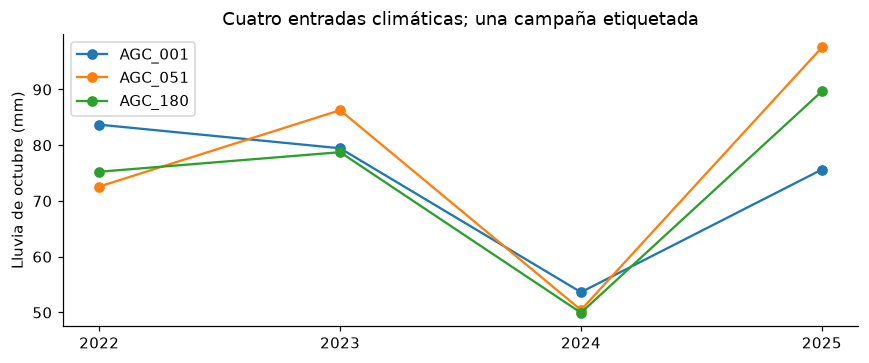

In [6]:
def variables_octubre(fuente):
    cols = ["P_2022_mm","P_2023_mm","P_2024_mm","P_2025_mm"]
    if not {"ID_POLIGONO",*cols} <= set(fuente):
        raise ValueError("Se requieren ID y cuatro lluvias de octubre")
    ids = fuente.ID_POLIGONO
    if fuente.empty or ids.isna().any() or ids.duplicated().any() or not ids.astype(str).str.fullmatch(r"AGC_\d{3}").all():
        raise ValueError("IDs vacíos, duplicados o mal formados")
    p = fuente.set_index("ID_POLIGONO")[cols].astype(float).sort_index()
    if not np.isfinite(p).all().all() or p.lt(0).any().any():
        raise ValueError("Lluvia ausente, no finita o negativa; no imputar")
    h = p[cols[:3]].mean(axis=1)
    if not h.ge(1).all():
        raise ValueError("H menor a 1 mm; se detiene el porcentaje")
    return pd.DataFrame({"H_mm":h,"P_actual_mm":p[cols[3]],
                         "A_mm":p[cols[3]]-h,"A_pct":100*(p[cols[3]]-h)/h})

variables = variables_octubre(fuente)
control_v = fuente.set_index("ID_POLIGONO").sort_index()
np.testing.assert_allclose(variables,control_v[variables.columns],atol=1e-9,rtol=0)
assert len(variables) == 197
display(pd.concat([control_v.loc[["AGC_001","AGC_051","AGC_180"],["P_2022_mm","P_2023_mm","P_2024_mm","P_2025_mm"]],
                   variables.loc[["AGC_001","AGC_051","AGC_180"]]],axis=1))
print("197 fórmulas reconstruidas desde cuatro lluvias; cero ajustes y cero nueva extracción.")
fig,ax = plt.subplots(figsize=(8,3.4))
for pid in ["AGC_001","AGC_051","AGC_180"]:
    ax.plot([2022,2023,2024,2025],control_v.loc[pid,["P_2022_mm","P_2023_mm","P_2024_mm","P_2025_mm"]],marker="o",label=pid)
ax.set(xticks=[2022,2023,2024,2025],ylabel="Lluvia de octubre (mm)",title="Cuatro entradas climáticas; una campaña etiquetada")
ax.legend(); fig.tight_layout(); plt.show()

## 3. Qué se mantiene fijo y qué cambia

| Receta | Numéricas | Pregunta |
| --- | --- | --- |
| R9_PCT | A_pct | Control del porcentaje de V2 |
| R9_P | P | Control de R9_RAW de V2 |
| R9_H | H | ¿Historia sola agrega información al municipio? |
| R9_HP | H y P | ¿La combinación aditiva mejora esas alternativas? |

Todos: **nueve municipios, medias municipales no penalizadas, Ridge residual y
misma rejilla**. MUN y MIX conservan sus recetas; J5_PCT es contexto histórico.
Los contrastes comparan procedimientos predictivos, no efectos agronómicos causales.

El porcentaje es una razón no lineal: no es cambiar unidades de H+P. Una columna
creada antes del modelo puede contener una interacción que dos pendientes aditivas
no representan. Eso no demuestra que toda familia no lineal gane.

In [7]:
CANDIDATOS = ["R9_PCT","R9_P","R9_H","R9_HP"]
MODELOS = ["MUN","MIX","J5_PCT"]+CANDIDATOS
ESPEC = {"R9_PCT":["A_pct"],"R9_P":["P_actual_mm"],"R9_H":["H_mm"],"R9_HP":["H_mm","P_actual_mm"]}
GRID = ["baseline",.01,.1,1.,10.,100.]
display(pd.DataFrame([{"procedimiento":m,"variables":", ".join(c),"columnas":len(c)} for m,c in ESPEC.items()]))
# Ejemplo inventado, sin rendimiento ni entrenamiento: igual exceso, distinto porcentaje.
ejemplo = pd.DataFrame({"H_mm":[50.,100.],"P_actual_mm":[70.,120.]})
ejemplo["A_mm"] = ejemplo.P_actual_mm-ejemplo.H_mm
ejemplo["A_pct"] = 100*ejemplo.A_mm/ejemplo.H_mm
display(ejemplo)
print("Ejemplo sintético: 20 mm de exceso no equivalen al mismo porcentaje; no prueba causalidad.")

,procedimiento,variables,columnas
0,R9_PCT,A_pct,1
1,R9_P,P_actual_mm,1
2,R9_H,H_mm,1
3,R9_HP,"H_mm, P_actual_mm",2


,H_mm,P_actual_mm,A_mm,A_pct
0,50.0,70.0,20.0,40.0
1,100.0,120.0,20.0,20.0


Ejemplo sintético: 20 mm de exceso no equivalen al mismo porcentaje; no prueba causalidad.


El ajuste original centró X e y dentro del municipio usando **solo entrenamiento**:
$u_j=X_j-\bar X_{g,j}$, $v=y-\bar y_g$, $s_j=\sqrt{\mathrm{media}(u_j^2)}$,
$Z_j=u_j/s_j$. Ridge minimiza $\|v-Z\beta\|^2+\alpha\|\beta\|^2$.

En HP el mismo alpha penaliza ambas pendientes, con escala propia por columna.
Singleton: u=0 y participa en la escala. Columna degenerada si
s≤1e−12·max(1,max|X_train|); se anula solo esa columna. Baseline: todas β=0.
Municipio no visto: media global, sin corrección numérica.
Predicción en municipio conocido: $\bar y_g+\sum_j\beta_j(X_j-\bar X_{g,j})/s_j$.
La pendiente en unidades originales es β/s. H y P correlacionadas dificultan
interpretar cada coeficiente como una contribución física independiente.

El lector muestra parámetros guardados; **no calcula ni aprende esas pendientes**.

## 4. Particiones fijas y selección verificable

CSV originales: cinco pliegues × diez repeticiones; cuatro interiores contenidos
en cada entrenamiento exterior. Parcela es la unidad, no cada observación climática.
No regeneramos semillas ni modificamos etiquetas de entrenamiento.

In [8]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

Selector original: RMSE de **todos** los errores interiores concatenados, no
promedio de cuatro RMSE ni el RMSE interior «visto». Empate ≤1e−12: baseline,
después alpha mayor. Cambia el escenario de evaluación exterior, **no el selector**.

Presupuesto histórico: 4,800 evaluaciones interiores (800 baseline y 4,000 Ridge),
200 reajustes exteriores; MUN se reprodujo 50 veces como control. Las repeticiones
posteriores comprobaron determinismo, no buscaron variantes. Aquí verificamos
200 elecciones desde 1,200 scores: **presupuesto actual de entrenamiento cero**.

In [9]:
def seleccionar_alpha_guardado(scores):
    cols = ["modelo","repeticion","pliegue","alpha","RMSE_interior"]
    if not set(cols) <= set(scores) or scores.empty or scores.duplicated(cols[:4]).any():
        raise ValueError("Scores ausentes o claves repetidas")
    if not np.isfinite(scores.RMSE_interior).all() or scores.RMSE_interior.lt(0).any():
        raise ValueError("Scores no finitos o negativos")
    filas = []
    for (m,r,f),q in scores.groupby(cols[:3],sort=True):
        q = q.copy(); q["clave"] = q.alpha.map(lambda a:"baseline" if a == "baseline" else float(a))
        if len(q) != 6 or set(q.clave) != set(GRID):
            raise ValueError("Se requieren los seis alphas registrados")
        minimo = q.RMSE_interior.min()
        empate = q.loc[q.RMSE_interior.le(minimo+1e-12),"clave"].tolist()
        elegido = "baseline" if "baseline" in empate else max(empate)
        filas.append({"modelo":m,"repeticion":r,"pliegue":f,"alpha_elegido":str(elegido)})
    return pd.DataFrame(filas)

seleccion = leer_csv("seleccion","scores_guardados")
assert len(seleccion) == 1200 and set(seleccion.modelo) == set(CANDIDATOS)
assert seleccion.n_ajustes.eq(4).all() and seleccion.n_ajustes_degenerados.eq(0).all()
decisiones = seleccionar_alpha_guardado(seleccion)
assert len(decisiones) == 200
assert set(map(tuple,decisiones[["modelo","repeticion","pliegue"]].to_numpy())) == {(m,r,f) for m in CANDIDATOS for r in range(10) for f in range(5)}
elegidos_guardados = seleccion.loc[seleccion.elegido,["modelo","repeticion","pliegue","alpha"]].rename(columns={"alpha":"alpha_elegido"})
assert len(elegidos_guardados) == 200
d = decisiones.merge(elegidos_guardados,on=["modelo","repeticion","pliegue"],validate="one_to_one",suffixes=("","_control"))
np.testing.assert_array_equal(d.alpha_elegido,d.alpha_elegido_control)
assert PRE["presupuesto"] == {"internas":4800,"baseline":800,"ridge":4000,"exteriores":200,"control_MUN":50}
assert REG["presupuesto"] == {"evaluaciones_internas":4800,"baseline_interno":800,"ajustes_ridge_internos":4000,"reajustes_exteriores":200,"controles_MUN":50}
display(decisiones.groupby(["modelo","alpha_elegido"]).size().rename("pliegues").to_frame())
display(seleccion.loc[seleccion.modelo.eq("R9_H")&seleccion.repeticion.eq(0)&seleccion.pliegue.eq(0),
                      ["alpha","RMSE_interior","RMSE_interior_visto","elegido"]])
print("200 decisiones desde 1,200 scores guardados; RMSE_interior_visto no selecciona.")

pliegues
modelo alpha_elegido          
R9_H   0.01                  2
       1.0                   2
       10.0                 14
       100.0                19
       baseline             13
R9_HP  0.01                  2
       0.1                   2
       1.0                  21
       10.0                  9
       100.0                 1
       baseline             15
R9_P   0.01                  1
       10.0                  4
       100.0                13
       baseline             32
R9_PCT 0.01                  5
       1.0                   4
       10.0                 23
       100.0                17
       baseline              1

,alpha,RMSE_interior,RMSE_interior_visto,elegido
600,baseline,0.468832,0.437436,True
601,0.01,0.471013,0.439838,False
602,0.1,0.471007,0.439831,False
603,1.0,0.470949,0.439767,False
604,10.0,0.470460,0.439229,False
605,100.0,0.468997,0.437617,False


200 decisiones desde 1,200 scores guardados; RMSE_interior_visto no selecciona.


In [10]:
parametros = leer_csv("parametros","parametros_guardados")
assert len(parametros) == 250 and set(parametros.modelo) == set(CANDIDATOS)
assert not parametros.duplicated(["modelo","repeticion","pliegue","variable"]).any()
assert np.isfinite(parametros[["beta_estandarizada","escala","pendiente_unidad_original"]]).all().all()
assert parametros.escala.gt(0).all() and not parametros.columna_degenerada.any()
for m,cs in ESPEC.items():
    q = parametros.loc[parametros.modelo.eq(m)]
    assert len(q) == 50*len(cs) and set(q.variable) == set(cs)
    assert q.groupby(["repeticion","pliegue"]).size().eq(len(cs)).all()
np.testing.assert_allclose(parametros.beta_estandarizada/parametros.escala,parametros.pendiente_unidad_original,atol=1e-12,rtol=0)
p = parametros.merge(decisiones,on=["modelo","repeticion","pliegue"],validate="many_to_one")
np.testing.assert_array_equal(p.alpha,p.alpha_elegido)
display(parametros.groupby(["modelo","variable"]).agg(escala_mediana=("escala","median"),
         beta_mediana=("beta_estandarizada","median"),pendiente_original_mediana=("pendiente_unidad_original","median")))
print("250 filas de parámetros corresponden a 200 modelos: HP guarda dos pendientes por modelo.")

escala_mediana  beta_mediana  pendiente_original_mediana
modelo variable                                                             
R9_H   H_mm               7.253253     -0.042787                   -0.005997
R9_HP  H_mm               7.253253     -0.176559                   -0.024533
       P_actual_mm        9.256042      0.108040                    0.012008
R9_P   P_actual_mm        9.256042      0.000000                    0.000000
R9_PCT A_pct              7.468228      0.096095                    0.012935

250 filas de parámetros corresponden a 200 modelos: HP guarda dos pendientes por modelo.


## 5. Controles de continuidad con V2

Antes de interpretar H/HP, la corrida original reprodujo PCT y P frente a V2:
100 elecciones idénticas y 2×1,380 predicciones a tolerancia 1e−8 t/ha. Las
referencias MUN/MIX/J5 también conservan sus claves y objetivos. Aquí comprobamos
las salidas guardadas entre rondas; no ejecutamos los ajustes que las produjeron.

El primer intento se detuvo por leer `alpha` vacío en vez de **`alpha_estado`**
del control V2. No llegó a las métricas H/HP. r1 corrigió solo el lector, conservó
el fallo y registró antes de reiniciar: no fue una búsqueda motivada por resultados.

In [11]:
oof = leer_csv("oof","resultados_guardados")
v2 = leer_csv("v2_oof","resultados_guardados")
assert len(oof) == 9660 and set(oof.modelo) == set(MODELOS)
assert not oof.duplicated(["modelo"]+claves).any()
esperado = set(map(tuple,validaciones[claves].to_numpy()))
y = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
for m,q in oof.groupby("modelo"):
    assert len(q) == 1380 and set(map(tuple,q[claves].to_numpy())) == esperado
    assert q.ID_POLIGONO.nunique() == 138 and np.isfinite(q.predicho).all()
    np.testing.assert_array_equal(q.observado,q.ID_POLIGONO.map(y))
    for c in ["Municipio","grupo_J5","celda_centroide"]:
        np.testing.assert_array_equal(q[c],q.ID_POLIGONO.map(grupos[c]))
    np.testing.assert_array_equal(q.zona,np.where(q.Municipio.eq("Chignahuapan"),"Chignahuapan","resto"))
for m,anterior in [("R9_PCT","R9_PCT"),("R9_P","R9_RAW"),("MUN","MUN"),("MIX","MIX"),("J5_PCT","J5_PCT")]:
    a = oof.loc[oof.modelo.eq(m)].set_index(claves).sort_index()
    b = v2.loc[v2.modelo.eq(anterior)].set_index(claves).sort_index()
    assert a.index.equals(b.index)
    np.testing.assert_array_equal(a.observado,b.observado)
    np.testing.assert_allclose(a.predicho,b.predicho,atol=1e-8,rtol=0)
    if m in {"R9_PCT","R9_P"}:
        for _,q in b.reset_index().groupby(["repeticion","pliegue"]):
            alpha_v2 = q.alpha_estado.dropna().astype(str).str.split("|",regex=False).str[0].unique()
            assert len(alpha_v2) == 1
            r,f = q.repeticion.iloc[0],q.pliegue.iloc[0]
            nuevo = decisiones.loc[decisiones.modelo.eq(m)&decisiones.repeticion.eq(r)&decisiones.pliegue.eq(f),"alpha_elegido"].item()
            assert nuevo == alpha_v2[0]
        np.testing.assert_array_equal(a.alpha,decisiones.set_index(["modelo","repeticion","pliegue"]).loc[(m,),"alpha_elegido"].reindex(a.index.droplevel("ID_POLIGONO")))
print("P/PCT: 100 elecciones y 2,760 predicciones guardadas conciliadas con V2; referencias intactas.")

P/PCT: 100 elecciones y 2,760 predicciones guardadas conciliadas con V2; referencias intactas.


## 6. Escenario principal fijado para esta ronda

V3 evalúa principalmente **municipios presentes en entrenamiento (SEEN135)**,
porque las 59 ocultas pertenecen a municipios con etiquetas. Esta decisión se
registró antes de ajustar V3, pero después de V2; no cambia su regla retrospectivamente.

Máscara solo con ID, Municipio y roles; idéntica para candidatos y referencias,
no la máscara particular de J5. Conserva 1,350 OOF por procedimiento sobre 135
parcelas repetidas. **No retira etiquetas del entrenamiento.** FULL138 y los 30
casos de municipio no visto se conservan como escenarios secundarios.

In [12]:
filas_mascara = []
for (r,f),q in externas.groupby(["repeticion","pliegue"]):
    mun_train = set(q.loc[q.rol.eq("entrenamiento"),"ID_POLIGONO"].map(grupos.Municipio))
    v = q.loc[q.rol.eq("validacion"),claves].copy()
    v["municipio_visto"] = v.ID_POLIGONO.map(grupos.Municipio).isin(mun_train)
    filas_mascara.append(v)
mascara = pd.concat(filas_mascara,ignore_index=True)
assert len(mascara) == 1380 and not mascara.duplicated(claves).any()
assert mascara.municipio_visto.sum() == 1350
check_m = oof.merge(mascara,on=claves,validate="many_to_one",suffixes=("_guardado",""))
np.testing.assert_array_equal(check_m.municipio_visto_guardado,check_m.municipio_visto)
seen = oof.loc[oof.municipio_visto].copy()
no_vistos = oof.loc[~oof.municipio_visto].copy()
assert len(seen) == 9450 and seen.ID_POLIGONO.nunique() == 135
assert len(no_vistos) == 210 and no_vistos.ID_POLIGONO.nunique() == 3
ESCENARIOS = {"municipio_visto":seen,"todas":oof,"municipio_no_visto":no_vistos}
display(mascara.groupby("municipio_visto").agg(oof=("ID_POLIGONO","size"),parcelas=("ID_POLIGONO","nunique")))

,oof,parcelas
municipio_visto,,
False,30,3
True,1350,135


## 7. Un mejor RMSE aislado no basta

Puntuar cada error fuera de muestra, sin promediar las diez predicciones de una
parcela ni los RMSE de pliegues. RMSE y MAE están en t/ha; R² no. Son 138 etiquetas,
no 9,660 observaciones independientes. R² se deja sin definir si la varianza del
objetivo es nula o numéricamente degenerada; las dos métricas de error sí existen.

,n_oof,n_parcelas,RMSE,MAE,R2
MUN,1350.0,135.0,0.493404,0.321274,0.657475
MIX,1350.0,135.0,0.487197,0.334215,0.666039
J5_PCT,1350.0,135.0,0.481145,0.328772,0.674283
R9_PCT,1350.0,135.0,0.485093,0.324697,0.668917
R9_P,1350.0,135.0,0.495045,0.323981,0.655192
R9_H,1350.0,135.0,0.494616,0.328602,0.655791
R9_HP,1350.0,135.0,0.493092,0.329713,0.657908


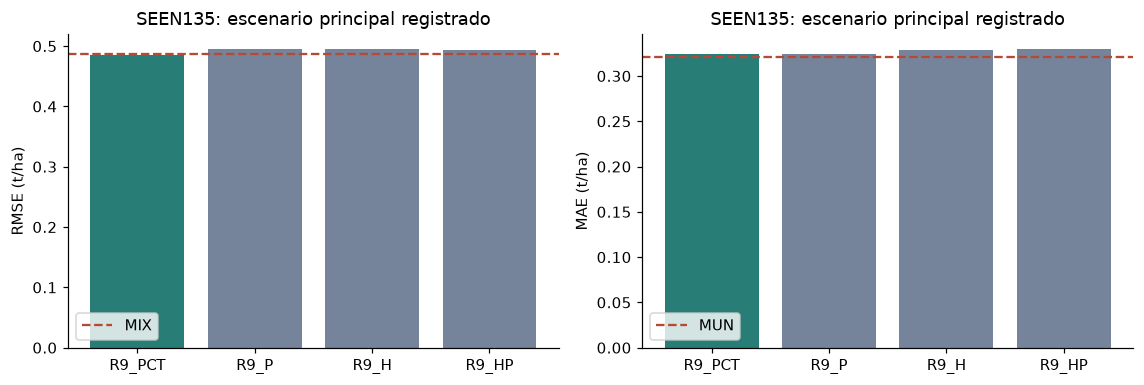

In [13]:
def metricas(df):
    y,p = df.observado.to_numpy(float),df.predicho.to_numpy(float)
    if len(y) == 0 or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Métricas vacías o no finitas")
    e = p-y; sst = np.sum((y-y.mean())**2)
    return pd.Series({"n_oof":len(df),"n_parcelas":df.ID_POLIGONO.nunique(),
                      "RMSE":np.sqrt(np.mean(e**2)),"MAE":np.mean(np.abs(e)),
                      "R2":1-np.sum(e**2)/sst if sst > 1e-12 else np.nan})

def tabla_metricas(df):
    return pd.DataFrame({m:metricas(q) for m,q in df.groupby("modelo")}).T.reindex(MODELOS)

metricas_esc = pd.concat([tabla_metricas(q).rename_axis("modelo").reset_index().assign(escenario=s)
                          for s,q in ESCENARIOS.items()],ignore_index=True)
ctrl_m = leer_csv("metricas_control","control_posterior")
orden = ["escenario","modelo"]
a,b = metricas_esc.set_index(orden).sort_index(),ctrl_m.set_index(orden).sort_index()
assert a.index.equals(b.index)
np.testing.assert_allclose(a,b[a.columns],atol=1e-12,rtol=0,equal_nan=True)
por_rep = pd.DataFrame([{"escenario":s,"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                        for s,df in ESCENARIOS.items() for (m,r),q in df.groupby(["modelo","repeticion"])])
ctrl_r = leer_csv("repeticiones_control","control_posterior").set_index(["escenario","modelo","repeticion"]).sort_index()
a = por_rep.set_index(ctrl_r.index.names).sort_index()
assert a.index.equals(ctrl_r.index)
np.testing.assert_allclose(a,ctrl_r[a.columns],atol=1e-12,rtol=0,equal_nan=True)
principales = tabla_metricas(seen)
full = tabla_metricas(oof)
display(principales)
fig,axes = plt.subplots(1,2,figsize=(10.5,3.6))
for ax,met,ref in zip(axes,["RMSE","MAE"],["MIX","MUN"]):
    ax.bar(CANDIDATOS,principales.loc[CANDIDATOS,met],color=["#287d77"]+["#75849b"]*3)
    ax.axhline(principales.loc[ref,met],color="#b64834",ls="--",label=ref)
    ax.set(ylabel=f"{met} (t/ha)",title="SEEN135: escenario principal registrado")
    ax.legend()
fig.tight_layout(); plt.show()

Regla interna de desarrollo, **no test de significación ni puntuación oficial de
FIRA**: RMSE<MIX y MAE≤MUN agrupados, cada condición en al menos 8/10 repeticiones.
Los diez conteos describen estabilidad; no son diez estudios independientes.

In [14]:
def regla_avance(df):
    g = tabla_metricas(df)
    reps = pd.DataFrame([{"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                         for (m,r),q in df.groupby(["modelo","repeticion"])])
    R = reps.pivot(index="repeticion",columns="modelo",values="RMSE")
    A = reps.pivot(index="repeticion",columns="modelo",values="MAE")
    if set(R.index) != set(range(10)) or set(R.columns) != set(MODELOS) or R.isna().any().any() or A.isna().any().any():
        raise ValueError("Repeticiones/modelos incompletos")
    filas = []
    for m in CANDIDATOS:
        nr,na = int((R[m]<R.MIX).sum()),int((A[m]<=A.MUN).sum())
        drm,dma = float(g.loc[m,"RMSE"]-g.loc["MIX","RMSE"]),float(g.loc[m,"MAE"]-g.loc["MUN","MAE"])
        filas.append({"modelo":m,"RMSE":g.loc[m,"RMSE"],"MAE":g.loc[m,"MAE"],
                      "delta_RMSE_MIX":drm,"delta_MAE_MUN":dma,"reps_RMSE_MIX":nr,"reps_MAE_MUN":na,
                      "cumple":bool(drm<0 and dma<=0 and nr>=8 and na>=8)})
    return pd.DataFrame(filas)

regla = pd.concat([regla_avance(df).assign(escenario=s) for s,df in [("municipio_visto",seen),("todas",oof)]],ignore_index=True)
ctrl_regla = leer_csv("regla_control","control_posterior")
a,b = regla.set_index(["escenario","modelo"]).sort_index(),ctrl_regla.set_index(["escenario","modelo"]).sort_index()
assert a.index.equals(b.index)
np.testing.assert_allclose(a.select_dtypes(exclude="bool"),b[a.select_dtypes(exclude="bool").columns],atol=1e-12,rtol=0)
np.testing.assert_array_equal(a.cumple,b.cumple)
assert not regla.cumple.any()
display(regla.loc[regla.escenario.eq("municipio_visto")])
print("Ninguna receta avanza. PCT mejora RMSE agrupado a MIX, pero solo en 6/10 y con MAE peor que MUN.")

,modelo,RMSE,MAE,delta_RMSE_MIX,delta_MAE_MUN,reps_RMSE_MIX,reps_MAE_MUN,cumple,escenario
0,R9_PCT,0.485093,0.324697,-0.002104,0.003423,6,2,False,municipio_visto
1,R9_P,0.495045,0.323981,0.007849,0.002707,1,1,False,municipio_visto
2,R9_H,0.494616,0.328602,0.007419,0.007328,2,0,False,municipio_visto
3,R9_HP,0.493092,0.329713,0.005895,0.008440,2,1,False,municipio_visto


Ninguna receta avanza. PCT mejora RMSE agrupado a MIX, pero solo en 6/10 y con MAE peor que MUN.


## 8. Qué responde cada contraste

HP−H y HP−P evalúan añadir una columna bajo el mismo procedimiento; al reajustar
conjuntamente también pueden cambiar pendientes y alpha. H−PCT y HP−PCT comparan
representaciones. No son aislamiento causal de historia ni de lluvia de 2025.
Una diferencia agrupada pequeña debe leerse junto a MAE y repeticiones.

In [15]:
PARES = [("R9_HP","R9_H","adición de P a H"),("R9_HP","R9_P","adición de H a P"),
         ("R9_H","R9_PCT","histórico frente a razón"),("R9_HP","R9_PCT","aditivo frente a razón")]
filas = []
for s in ["municipio_visto","todas"]:
    mm = metricas_esc.loc[metricas_esc.escenario.eq(s)].set_index("modelo")
    rr = por_rep.loc[por_rep.escenario.eq(s)].set_index(["modelo","repeticion"])
    for m,b,label in PARES:
        for met in ["RMSE","MAE"]:
            delta = rr.loc[m,met]-rr.loc[b,met]
            filas.append({"escenario":s,"contraste":label,"modelo":m,"referencia":b,"metrica":met,
                          "delta_agrupado":float(mm.loc[m,met]-mm.loc[b,met]),"repeticiones_mejora":int(delta.lt(0).sum())})
contrastes = pd.DataFrame(filas)
ctrl_c = leer_csv("contrastes_control","control_posterior").set_index(["escenario","modelo","referencia","metrica"]).sort_index()
c = contrastes.set_index(ctrl_c.index.names).sort_index()
assert c.index.equals(ctrl_c.index)
np.testing.assert_array_equal(c.contraste,ctrl_c.contraste)
np.testing.assert_allclose(c[["delta_agrupado","repeticiones_mejora"]],ctrl_c[["delta_agrupado","repeticiones_mejora"]],atol=1e-12,rtol=0)
display(contrastes.loc[contrastes.escenario.eq("municipio_visto")])
print("H y HP quedan detrás de PCT en RMSE en 10/10 repeticiones; HP−H cambia RMSE y MAE en sentidos opuestos.")

,escenario,contraste,modelo,referencia,metrica,delta_agrupado,repeticiones_mejora
0,municipio_visto,adición de P a H,R9_HP,R9_H,RMSE,-0.001524,6
1,municipio_visto,adición de P a H,R9_HP,R9_H,MAE,0.001111,4
2,municipio_visto,adición de H a P,R9_HP,R9_P,RMSE,-0.001954,6
3,municipio_visto,adición de H a P,R9_HP,R9_P,MAE,0.005733,2
4,municipio_visto,histórico frente a razón,R9_H,R9_PCT,RMSE,0.009523,0
5,municipio_visto,histórico frente a razón,R9_H,R9_PCT,MAE,0.003905,1
6,municipio_visto,aditivo frente a razón,R9_HP,R9_PCT,RMSE,0.007999,0
7,municipio_visto,aditivo frente a razón,R9_HP,R9_PCT,MAE,0.005016,2


H y HP quedan detrás de PCT en RMSE en 10/10 repeticiones; HP−H cambia RMSE y MAE en sentidos opuestos.


**Lectura:** H sola no sustituye al porcentaje en estas recetas; agregar P a H
baja RMSE unos 0.0015 t/ha y empeora MAE unos 0.0011. PCT es más competitivo,
pero tampoco avanza. Se cuestiona «la señal viene del histórico más que de la
desviación de 2025»; no se concluye que H, octubre o el clima sean inútiles.

## 9. Territorio y regularización

El problema dentro de Chignahuapan no se resuelve con H ni HP. Leer los errores
por territorio evita confundir una mejora entre municipios con otra dentro de uno.
Pendiente cero es decisión del selector, no ausencia demostrada de un efecto físico.
R² en municipios con un único rendimiento no es informativo.

**Precisión de presentación:** el CSV histórico de Tepeapulco contiene 14 R²
extremos: 4.45 repetido diez veces dejó una suma de cuadrados de apenas
7.9·10⁻³⁰ por redondeo. Aquí sst≤1e−12 se muestra como NaN (no definido),
preservando ese CSV. RMSE, MAE, resultados globales y regla no cambian.

In [16]:
zonas = pd.DataFrame([{"escenario":s,"modelo":m,"zona":z,**metricas(q).to_dict()}
                      for s,df in ESCENARIOS.items() for (m,z),q in df.groupby(["modelo","zona"])])
ctrl_z = leer_csv("zonas_control","control_posterior").set_index(["escenario","modelo","zona"]).sort_index()
z = zonas.set_index(ctrl_z.index.names).sort_index()
assert z.index.equals(ctrl_z.index)
np.testing.assert_allclose(z,ctrl_z[z.columns],atol=1e-12,rtol=0,equal_nan=True)
municipios = pd.DataFrame([{"escenario":s,"modelo":m,"Municipio":mun,**metricas(q).to_dict()}
                           for s,df in ESCENARIOS.items() for (m,mun),q in df.groupby(["modelo","Municipio"])])
ctrl_mun = leer_csv("municipios_control","control_posterior").set_index(["escenario","modelo","Municipio"]).sort_index()
a = municipios.set_index(ctrl_mun.index.names).sort_index()
assert a.index.equals(ctrl_mun.index)
np.testing.assert_allclose(a[["n_oof","n_parcelas","RMSE","MAE"]],ctrl_mun[["n_oof","n_parcelas","RMSE","MAE"]],atol=1e-12,rtol=0)
informativo = a.R2.notna()
np.testing.assert_allclose(a.loc[informativo,"R2"],ctrl_mun.loc[informativo,"R2"],atol=1e-12,rtol=0)
r2_redondeo = (~informativo)&np.isfinite(ctrl_mun.R2)
assert int(r2_redondeo.sum()) == 14
# R² degenerado: NaN pedagógico en vez de cociente amplificado por redondeo.
display(zonas.loc[zonas.escenario.eq("municipio_visto"),["modelo","zona","n_parcelas","RMSE","MAE"]])
ceros = decisiones.alpha_elegido.eq("baseline").groupby(decisiones.modelo).sum().astype(int)
assert ceros.to_dict() == {"R9_H":13,"R9_HP":15,"R9_P":32,"R9_PCT":1}
display(ceros.rename("pendiente_cero_en_50").to_frame())
print("14 R² municipales espurios se muestran como NaN; no se cambia ningún CSV ni error de predicción.")

,modelo,zona,n_parcelas,RMSE,MAE
0,J5_PCT,Chignahuapan,71.0,0.574432,0.384969
1,J5_PCT,resto,64.0,0.349656,0.266428
2,MIX,Chignahuapan,71.0,0.573628,0.389104
3,MIX,resto,64.0,0.368299,0.273322
4,MUN,Chignahuapan,71.0,0.590198,0.381019
5,MUN,resto,64.0,0.356496,0.254994
6,R9_H,Chignahuapan,71.0,0.588236,0.382799
7,R9_H,resto,64.0,0.363565,0.268477
8,R9_HP,Chignahuapan,71.0,0.587500,0.384817
9,R9_HP,resto,64.0,0.360505,0.268583


,pendiente_cero_en_50
modelo,
R9_H,13
R9_HP,15
R9_P,32
R9_PCT,1


14 R² municipales espurios se muestran como NaN; no se cambia ningún CSV ni error de predicción.


## 10. Municipio visto no equivale a la entrega

Todas las 59 ocultas tienen municipio con etiquetas, pero cambian las proporciones
territoriales y el entrenamiento final (138 frente a 110–111 en CV). En Nanacamilpa
solo AGC_048 está etiquetada y AGC_120 oculta: no existe OOF equivalente a
entrenar con la única etiqueta y validar otra parcela de ese municipio.

Los rangos siguientes describen soporte, **no precisión**. No reponderamos para
elegir ganador ni calculamos rendimientos ocultos. Fuera de rango municipal
univariado no demuestra por sí solo estar fuera del soporte multivariado global.

In [17]:
def soporte_entrega(variables,externas):
    requeridas = {"ID_POLIGONO","Municipio","CONJUNTO","H_mm","P_actual_mm","A_pct"}
    if not requeridas <= set(variables) or variables.ID_POLIGONO.duplicated().any():
        raise ValueError("Metadatos o claves de soporte inválidas")
    if variables[list(requeridas)].isna().any().any() or not np.isfinite(variables[["H_mm","P_actual_mm","A_pct"]]).all().all():
        raise ValueError("Soporte con entradas ausentes o no finitas")
    if set(variables.CONJUNTO) != {"ENTRENAMIENTO","PREDICCION"}:
        raise ValueError("Roles oficiales incompatibles")
    meta = variables.set_index("ID_POLIGONO")
    if not set(externas.ID_POLIGONO) <= set(meta.index):
        raise ValueError("Particiones con IDs fuera de la tabla")
    n_ocultas = int(variables.CONJUNTO.eq("PREDICCION").sum())
    if n_ocultas == 0:
        raise ValueError("Sin parcelas ocultas para describir soporte")
    filas = []
    for mun,q in variables.groupby("Municipio",sort=True):
        tr,te = q.loc[q.CONJUNTO.eq("ENTRENAMIENTO")],q.loc[q.CONJUNTO.eq("PREDICCION")]
        total,visto,una = 0,0,0
        for _,pa in externas.groupby(["repeticion","pliegue"]):
            nt = int(meta.loc[pa.loc[pa.rol.eq("entrenamiento"),"ID_POLIGONO"],"Municipio"].eq(mun).sum())
            nv = int(meta.loc[pa.loc[pa.rol.eq("validacion"),"ID_POLIGONO"],"Municipio"].eq(mun).sum())
            total += nv; visto += nv if nt > 0 else 0; una += nv if nt == 1 else 0
        sin = len(tr) == 1 and len(te) > 0
        row = {"Municipio":mun,"n_etiquetadas":len(tr),"n_ocultas":len(te),"fraccion_ocultas":len(te)/n_ocultas,
               "n_oof":total,"n_oof_municipio_visto":visto,"n_oof_train_una_etiqueta":una,
               "caso_singleton_sin_validacion":sin,"nota":"Caso entrega con una etiqueta no evaluado" if sin else ""}
        for c in ["H_mm","P_actual_mm","A_pct"]:
            row[c+"_fuera_rango_municipal"] = int(((te[c]<tr[c].min())|(te[c]>tr[c].max())).sum()) if len(tr) else len(te)
        filas.append(row)
    return pd.DataFrame(filas)

meta_variables = grupos.drop(columns=variables.columns).join(variables).reset_index()
soporte = soporte_entrega(meta_variables,externas)
ctrl_s = leer_csv("soporte_control","control_posterior")
np.testing.assert_allclose(soporte.select_dtypes(include="number"),ctrl_s[soporte.select_dtypes(include="number").columns],atol=1e-12,rtol=0)
np.testing.assert_array_equal(soporte.caso_singleton_sin_validacion,ctrl_s.caso_singleton_sin_validacion)
np.testing.assert_array_equal(soporte.Municipio,ctrl_s.Municipio)
np.testing.assert_array_equal(soporte.nota,ctrl_s.nota.fillna(""))
assert soporte.n_etiquetadas.sum() == 138 and soporte.n_ocultas.sum() == 59
assert soporte.loc[soporte.caso_singleton_sin_validacion,"Municipio"].tolist() == ["Nanacamilpa de Mariano Arista"]
display(soporte[["Municipio","n_etiquetadas","n_ocultas","n_oof_municipio_visto","n_oof_train_una_etiqueta","caso_singleton_sin_validacion"]])
display(meta_variables.set_index("ID_POLIGONO").loc[["AGC_048","AGC_120"],["Municipio","CONJUNTO","celda_centroide","H_mm","P_actual_mm","A_pct"]])
display(soporte.loc[soporte.n_ocultas.gt(0),["Municipio","H_mm_fuera_rango_municipal","P_actual_mm_fuera_rango_municipal","A_pct_fuera_rango_municipal"]])

,Municipio,n_etiquetadas,n_ocultas,n_oof_municipio_visto,n_oof_train_una_etiqueta,caso_singleton_sin_validacion
0,Almoloya,10,4,100,0,False
1,Apan,1,0,0,0,False
2,Calpulalpan,30,14,300,0,False
3,Chignahuapan,71,29,710,0,False
4,Cuautepec de Hinojosa,5,4,50,0,False
5,Emiliano Zapata,3,0,30,14,False
6,Nanacamilpa de Mariano Arista,1,1,0,0,True
7,Singuilucan,16,7,160,0,False
8,Tepeapulco,1,0,0,0,False


,Municipio,CONJUNTO,celda_centroide,H_mm,P_actual_mm,A_pct
ID_POLIGONO,,,,,,
AGC_048,Nanacamilpa de Mariano Arista,ENTRENAMIENTO,R36_C28,72.093588,77.619867,7.665423
AGC_120,Nanacamilpa de Mariano Arista,PREDICCION,R37_C28,73.761738,75.767151,2.718771


,Municipio,H_mm_fuera_rango_municipal,P_actual_mm_fuera_rango_municipal,A_pct_fuera_rango_municipal
0,Almoloya,0,0,0
2,Calpulalpan,1,0,0
3,Chignahuapan,0,2,0
4,Cuautepec de Hinojosa,0,0,0
6,Nanacamilpa de Mariano Arista,1,1,1
7,Singuilucan,0,0,0


## 11. ¿Dónde se distribuyen las ganancias y pérdidas?

Ganancia SSE = error² MIX − error² candidato, positiva si el candidato mejora.
Se suman sobre las mismas claves parcela×repetición. Beneficio **neto** incluye
pérdidas; top5 parcelas y top2 celdas usan beneficio **bruto positivo**. No se
eliminan casos ni se repite la selección. Celda de centroide es agrupación
diagnóstica, no totalidad de píxeles aportantes ni tamaño muestral efectivo.

In [18]:
filas = []
for s,df in ESCENARIOS.items():
    mix = df.loc[df.modelo.eq("MIX")].set_index(claves).sort_index()
    for m in CANDIDATOS:
        p = df.loc[df.modelo.eq(m)].set_index(claves).sort_index()
        assert p.index.equals(mix.index)
        delta = p[["Municipio","celda_centroide"]].copy()
        delta["ganancia_SSE_vs_MIX"] = (mix.predicho-mix.observado)**2-(p.predicho-p.observado)**2
        q = delta.reset_index().groupby("ID_POLIGONO").agg(ganancia_SSE_vs_MIX=("ganancia_SSE_vs_MIX","sum"),
                                                           Municipio=("Municipio","first"),celda_centroide=("celda_centroide","first"))
        filas.append(q.reset_index().assign(escenario=s,modelo=m))
deltas = pd.concat(filas,ignore_index=True)
ctrl_d = leer_csv("deltas_control","control_posterior").set_index(["escenario","modelo","ID_POLIGONO"]).sort_index()
d = deltas.set_index(ctrl_d.index.names).sort_index()
assert d.index.equals(ctrl_d.index)
np.testing.assert_allclose(d.ganancia_SSE_vs_MIX,ctrl_d.ganancia_SSE_vs_MIX,atol=1e-12,rtol=0)
for c in ["Municipio","celda_centroide"]:
    np.testing.assert_array_equal(d[c],ctrl_d[c])
filas = []
for (s,m),q in deltas.groupby(["escenario","modelo"]):
    gain = q.ganancia_SSE_vs_MIX
    bruta = float(gain.clip(lower=0).sum())
    cells = q.groupby("celda_centroide").ganancia_SSE_vs_MIX.sum()
    bruta_celdas = float(cells.clip(lower=0).sum())
    filas.append({"escenario":s,"modelo":m,"ganancia_SSE_neta":float(gain.sum()),"ganancia_SSE_bruta_positiva":bruta,
                  "fraccion_mejora_bruta_top5_parcelas":float(gain.nlargest(5).clip(lower=0).sum())/bruta if bruta else np.nan,
                  "fraccion_mejora_bruta_top2_celdas_centroide":float(cells.nlargest(2).clip(lower=0).sum())/bruta_celdas if bruta_celdas else np.nan,
                  "n_parcelas_mejoran":int(gain.gt(0).sum()),"n_parcelas_empeoran":int(gain.lt(0).sum())})
concentracion = pd.DataFrame(filas)
ctrl_c = leer_csv("concentracion_control","control_posterior").set_index(["escenario","modelo"]).sort_index()
c = concentracion.set_index(ctrl_c.index.names).sort_index()
assert c.index.equals(ctrl_c.index)
np.testing.assert_allclose(c,ctrl_c[c.columns],atol=1e-12,rtol=0,equal_nan=True)
display(concentracion.loc[concentracion.escenario.eq("municipio_visto")])
print("Diagnóstico registrado: no se quitaron parcelas para ganar ni se estimó n efectivo por contar celdas.")

,escenario,modelo,ganancia_SSE_neta,ganancia_SSE_bruta_positiva,fraccion_mejora_bruta_top5_parcelas,fraccion_mejora_bruta_top2_celdas_centroide,n_parcelas_mejoran,n_parcelas_empeoran
4,municipio_visto,R9_H,-9.833668,30.710151,0.293884,0.559287,65,70
5,municipio_visto,R9_HP,-7.801516,30.462527,0.296733,0.595594,55,80
6,municipio_visto,R9_P,-10.407868,32.379250,0.330869,0.552543,83,52
7,municipio_visto,R9_PCT,2.761634,37.658019,0.272909,0.515206,68,67


Diagnóstico registrado: no se quitaron parcelas para ganar ni se estimó n efectivo por contar celdas.


## 12. Decisión, alcance y continuidad

- **Cerrar sin adopción:** H y HP no justifican aumentar el modelo bajo estas
  representaciones, esta ventana, Ridge y esta rejilla. PCT tampoco cumple la regla principal.
- **Corregir la interpretación fuerte:** la dependencia del porcentaje respecto
  de H no se convirtió en ventaja predictiva de H sola. Correlación entre variables
  no es aportación al rendimiento ni causalidad.
- Mantener MUN/MIX como referencias y J5_PCT como candidato histórico con reservas,
  no modelo final. Este experimento no identifica el motivo único de la ventaja de J5.
- Una campaña y etiquetas ya exploradas limitan generalización. SEEN135 no evalúa
  todo el soporte de las 59; no se inventa incertidumbre para AGC_120.

Reproducir fórmulas, métricas y decisiones guardadas verifica esta lectura, no
la paridad de reentrenamiento entre Python 3.12.14 histórico y Python 3.13 actual.
Las 34 pruebas y 9 autopruebas originales no se presentan como corridas aquí.
La siguiente ronda plantea otra hipótesis con registro propio; no se ejecuta aquí.

In [19]:
resumen = {"id":"EXP_05","modo":"lector_retrospectivo_sin_ajustes","parcelas":197,"etiquetas":138,
           "variables_recalculadas":True,"lluvias_reextraidas":False,"intersecciones_recalculadas":False,
           "procedimientos":7,"candidatos":4,"oof_por_procedimiento":1380,"oof_total":9660,
           "particiones_externas":50,"particiones_internas":200,"decisiones_verificadas":200,
           "scores_guardados_verificados":1200,"parametros_guardados":250,
           "ajustes_actuales":0,"predicciones_finales_generadas":0,"predicciones_recalculadas":False,
           "scores_interiores_recalculados":False,"metricas_recalculadas":True,
           "r2_municipales_presentacion_nan":int(r2_redondeo.sum()),
           "poblacion":"SEEN135","oof_seen_por_procedimiento":1350,"poblacion_secundaria":"FULL138",
           "regla_seen_cumplen":regla.loc[regla.escenario.eq("municipio_visto")&regla.cumple,"modelo"].tolist(),
           "regla_full_cumplen":regla.loc[regla.escenario.eq("todas")&regla.cumple,"modelo"].tolist(),
           "variantes_adoptadas":[],"candidato_historico_con_reservas":["J5_PCT"],
           "fecha_original_mexico":"2026-10-01","fecha_original_utc":"2026-10-02","fecha_adaptacion":"2026-10-08",
           "metricas_seen":principales[["RMSE","MAE","R2"]].to_dict(orient="index"),
           "metricas_full":full[["RMSE","MAE","R2"]].to_dict(orient="index"),
           "fecha_ejecucion_utc":datetime.now(timezone.utc).isoformat()}
print("RESUMEN_EXP_05_JSON="+json.dumps(resumen,sort_keys=True,ensure_ascii=False,allow_nan=False))

RESUMEN_EXP_05_JSON={"ajustes_actuales": 0, "candidato_historico_con_reservas": ["J5_PCT"], "candidatos": 4, "decisiones_verificadas": 200, "etiquetas": 138, "fecha_adaptacion": "2026-10-08", "fecha_ejecucion_utc": "2026-10-08T15:36:56.363387+00:00", "fecha_original_mexico": "2026-10-01", "fecha_original_utc": "2026-10-02", "id": "EXP_05", "intersecciones_recalculadas": false, "lluvias_reextraidas": false, "metricas_full": {"J5_PCT": {"MAE": 0.3291128347821879, "R2": 0.6801074895039918, "RMSE": 0.47966097284188197}, "MIX": {"MAE": 0.34171071524358665, "R2": 0.6609083799141191, "RMSE": 0.4938452449320888}, "MUN": {"MAE": 0.33539413463469375, "R2": 0.6358645937936154, "RMSE": 0.5117570123866723}, "R9_H": {"MAE": 0.3425629975443372, "R2": 0.6342363401744568, "RMSE": 0.5128999124804204}, "R9_HP": {"MAE": 0.34365032583561317, "R2": 0.6362837858052695, "RMSE": 0.511462360694685}, "R9_P": {"MAE": 0.33804228100790407, "R2": 0.6336578190253797, "RMSE": 0.5133053740415374}, "R9_PCT": {"MAE": 0.3

## Referencias y conceptos para profundizar (APA 7)

Equipo AgroCebada. (2026, 1 de octubre). *V3: protocolo de histórico y lluvia actual
de octubre, versión r1* [Registro interno exploratorio]. Su diseño y resultados
están incorporados; no se requiere otro documento. El fallo del lector alpha
se conserva como antecedente, no se atribuye a un cambio de hipótesis.

Funk, C., Peterson, P., Landsfeld, M., Pedreros, D., Verdin, J., Shukla, S., Husak,
G., Rowland, J., Harrison, L., Hoell, A., & Michaelsen, J. (2015). The climate hazards
infrared precipitation with stations—a new environmental record for monitoring
extremes. *Scientific Data, 2*, 150066. https://doi.org/10.1038/sdata.2015.66

National Centers for Environmental Information. (s. f.). *WMO climate normals*.
https://www.ncei.noaa.gov/products/wmo-climate-normals

scikit-learn developers. (s. f.). *Ridge*.
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

**Glosario:** H = media de tres octubres históricos; P = octubre de 2025;
aditivo = sumar contribuciones de columnas; razón = dividir P por H;
baseline = pendiente cero; OOF = predicción fuera del entrenamiento;
SEEN135 = municipio presente en entrenamiento; soporte = covariables y contexto
cubiertos, no rendimiento conocido. Aquí SEEN135 es principal registrado para V3,
no diagnóstico posterior de esta ronda ni una nueva muestra independiente.